In [10]:
import pandas as pd
from pathlib import Path

# ==========================================
# 1. LOAD CSV
# ==========================================

file_path = Path(r"D:\Pands Python\EmperorBulls\Book1.csv")

try:
    df = pd.read_csv(file_path, encoding="latin1")

    print("✅ Data Loaded Successfully!")
    print(f"File: {file_path}")
    
except FileNotFoundError:
    print("❌ File not found.")
    print(file_path)
    
except Exception as e:
    print(f"❌ Error: {e}")


# ==========================================
# 2. INSPECT DATA
# ==========================================

print("\n--- First 5 Rows ---")
print(df.head())

print("\n--- DataFrame Info ---")
df.info()

print("\n--- Shape ---")
print(f"Rows: {df.shape[0]}")
print(f"Columns: {df.shape[1]}")

print("\n--- Columns ---")
print(df.columns.tolist())

print("\n--- Missing Values ---")
print(df.isnull().sum())

print("\n--- Duplicate Rows ---")
print(df.duplicated().sum())

print("\n--- Data Types ---")
print(df.dtypes)

✅ Data Loaded Successfully!
File: D:\Pands Python\EmperorBulls\Book1.csv

--- First 5 Rows ---
   Lead ID First Contact Time                              Customer Name  \
0   7858.0   13-08-2026 17:17                                       Amar   
1   7829.0   13-08-2026 15:23                                    Unknown   
2   7805.0   13-08-2026 13:40                                 lvprtsngh_   
3   7798.0   13-08-2026 13:00                                    Unknown   
4   7783.0   13-08-2026 12:36  Shivam Sir zirakpur Emperor Emperor Bulls   

  Customer Number  WhatsApp Number         Branch Handler Name Latest Message  \
0    919501767757     9.170093e+11  Mohali Branch        Priya            NaN   
1    919478432054     9.170093e+11  Mohali Branch        Priya            NaN   
2    919914463072     9.170093e+11  Mohali Branch        Priya            NaN   
3    916284503653     9.170093e+11  Mohali Branch        Priya            NaN   
4    918427326098     9.170093e+11  Mohali 

In [11]:
import pandas as pd
import numpy as np
from datetime import datetime

# --- Load the data (if not already loaded) ---
# If df is not already loaded from Step 1, use this:
# df = pd.read_csv('Book1.csv')

print("="*60)
print("STEP 2: DATA CLEANING")
print("="*60)

# Create a copy to preserve original data
df_clean = df.copy()

# --- 1. Drop unnecessary columns ---
if 'Unnamed: 10' in df_clean.columns:
    df_clean = df_clean.drop('Unnamed: 10', axis=1)
    print("✓ Dropped 'Unnamed: 10' column")

# --- 2. Fix WhatsApp Number formatting ---
df_clean['WhatsApp Number'] = df_clean['WhatsApp Number'].astype(str).str.replace('.0', '')
df_clean['WhatsApp Number'] = df_clean['WhatsApp Number'].apply(
    lambda x: str(int(float(x))) if x.replace('.', '').replace('e+', '').replace('-', '').isdigit() else x
)
print("✓ Fixed WhatsApp Number formatting")

# --- 3. Clean Customer Number ---
df_clean['Customer Number'] = df_clean['Customer Number'].astype(str).str.replace('.0', '')
print("✓ Cleaned Customer Number formatting")

# --- 4. Convert Date columns to datetime ---
df_clean['First Contact Time'] = pd.to_datetime(df_clean['First Contact Time'], format='%d-%m-%Y %H:%M')
df_clean['Last Updated Time'] = pd.to_datetime(df_clean['Last Updated Time'], format='%d-%m-%Y %H:%M')
print("✓ Converted date columns to datetime")

# --- 5. Handle Customer Name ---
unknown_count = (df_clean['Customer Name'] == 'Unknown').sum()
known_count = len(df_clean) - unknown_count
print(f"✓ Customer Name - Known: {known_count}, Unknown: {unknown_count}")

# --- 6. Clean Latest Message column ---
df_clean['Latest Message'] = df_clean['Latest Message'].fillna('')
message_count = (df_clean['Latest Message'] != '').sum()
print(f"✓ Messages present: {message_count} records")

# --- 7. Basic Data Validation ---
print("\n--- Data Validation Summary ---")
print(f"Total Leads: {len(df_clean)}")
print(f"Branches: {df_clean['Branch'].unique().tolist()}")
print(f"Handlers: {df_clean['Handler Name'].unique().tolist()}")
print(f"Status: {df_clean['Status'].unique().tolist()}")

# Check for duplicate Lead IDs
duplicate_leads = df_clean['Lead ID'].duplicated().sum()
if duplicate_leads > 0:
    print(f"⚠️ Duplicate Lead IDs found: {duplicate_leads}")
else:
    print(f"✓ No duplicate Lead IDs found")

# --- 8. Create useful derived columns ---
df_clean['Contact Date'] = df_clean['First Contact Time'].dt.date
df_clean['Contact Hour'] = df_clean['First Contact Time'].dt.hour
df_clean['Contact Day'] = df_clean['First Contact Time'].dt.day_name()
df_clean['Contact Month'] = df_clean['First Contact Time'].dt.month_name()
df_clean['Time to Update (Hours)'] = (df_clean['Last Updated Time'] - df_clean['First Contact Time']).dt.total_seconds() / 3600

print("✓ Added derived columns: Contact Date, Hour, Day, Month, Time to Update")

# --- 9. Display cleaned data info ---
print("\n--- Cleaned Data Info ---")
print(df_clean.info())

print("\n--- Sample of Cleaned Data (First 10 rows) ---")
display_cols = ['Lead ID', 'Customer Name', 'WhatsApp Number', 'Branch', 'Handler Name', 
                'Latest Message', 'Status', 'Contact Date', 'Contact Hour']
print(df_clean[display_cols].head(10))

# --- 10. Summary Statistics ---
print("\n--- Summary Statistics ---")
print(f"Date Range: {df_clean['First Contact Time'].min()} to {df_clean['First Contact Time'].max()}")
print(f"\nStatus Distribution:")
print(df_clean['Status'].value_counts())
print(f"\nBranch Distribution:")
print(df_clean['Branch'].value_counts())
print(f"\nHandler Distribution:")
print(df_clean['Handler Name'].value_counts())

# --- 11. Save cleaned data ---
# df_clean.to_csv('Book1_cleaned.csv', index=False)
# print("✓ Cleaned data saved as 'Book1_cleaned.csv'")

print("\n" + "="*60)
print("DATA CLEANING COMPLETE")
print("="*60)

STEP 2: DATA CLEANING
✓ Dropped 'Unnamed: 10' column
✓ Fixed WhatsApp Number formatting
✓ Cleaned Customer Number formatting
✓ Converted date columns to datetime
✓ Customer Name - Known: 1158, Unknown: 3148
✓ Messages present: 1697 records

--- Data Validation Summary ---
Total Leads: 4306
Branches: ['Mohali Branch', 'frenchise', 'O-MAX Ludhiana', nan, 'hosirhrpur', 'Phagwara', 'moga', 'Ludhiana HQ', 'Ludhiana sec 32']
Handlers: ['Priya', 'Bandana', 'bandana', 'Raman', nan, 'lovenna', 'Manish', 'Ramandeep', 'Rajdeep', 'komal', 'Komal', 'Ankita']
Status: ['New', nan, 'student', 'not pick']
⚠️ Duplicate Lead IDs found: 13
✓ Added derived columns: Contact Date, Hour, Day, Month, Time to Update

--- Cleaned Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4306 entries, 0 to 4305
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   Lead ID                 4292 non-null   f

In [13]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

print("="*60)
print("STEP 3: DATA STANDARDIZATION & BUSINESS INSIGHTS")
print("="*60)

# --- 1. Handle Duplicate Lead IDs ---
print("\n--- Handling Duplicate Lead IDs ---")
duplicate_ids = df_clean[df_clean.duplicated(subset=['Lead ID'], keep=False)]
print(f"Found {len(duplicate_ids)} records with duplicate Lead IDs")
if len(duplicate_ids) > 0:
    # Keep the first occurrence, drop duplicates
    df_clean = df_clean.drop_duplicates(subset=['Lead ID'], keep='first')
    print(f"✓ Removed duplicates, now {len(df_clean)} unique leads")

# --- 2. Standardize Branch Names ---
print("\n--- Standardizing Branch Names ---")
branch_mapping = {
    'frenchise': 'Franchise',
    'hosirhrpur': 'Hoshiarpur',
    'moga': 'Moga',
    'O-MAX Ludhiana': 'Ludhiana O-MAX',
    'Ludhiana HQ': 'Ludhiana HQ',
    'Ludhiana sec 32': 'Ludhiana Sector 32',
    'Mohali Branch': 'Mohali',
    'Phagwara': 'Phagwara'
}
df_clean['Branch'] = df_clean['Branch'].replace(branch_mapping)
df_clean['Branch'] = df_clean['Branch'].fillna('Unknown Branch')
print(f"✓ Standardized branches. Unique branches: {df_clean['Branch'].unique().tolist()}")

# --- 3. Standardize Handler Names ---
print("\n--- Standardizing Handler Names ---")
handler_mapping = {
    'bandana': 'Bandana',
    'lovenna': 'Lovenna',
    'komal': 'Komal',
    'Ramandeep': 'Ramandeep',
    'Rajdeep': 'Rajdeep',
    'Manish': 'Manish',
    'Raman': 'Raman',
    'Ankita': 'Ankita',
    'Priya': 'Priya'
}
df_clean['Handler Name'] = df_clean['Handler Name'].replace(handler_mapping)
df_clean['Handler Name'] = df_clean['Handler Name'].fillna('Unknown Handler')
print(f"✓ Standardized handlers. Unique handlers: {df_clean['Handler Name'].unique().tolist()}")

# --- 4. Standardize Status ---
print("\n--- Standardizing Status ---")
status_mapping = {
    'New': 'New',
    'student': 'New',
    'not pick': 'Not Picked',
    np.nan: 'Unknown'
}
df_clean['Status'] = df_clean['Status'].replace(status_mapping)
df_clean['Status'] = df_clean['Status'].fillna('Unknown')
print(f"✓ Standardized status. Status distribution:")
print(df_clean['Status'].value_counts())

# --- 5. BUSINESS INSIGHTS ---

print("\n" + "="*60)
print("BUSINESS INSIGHTS")
print("="*60)

# 5.1 Lead Volume by Branch
print("\n--- 1. Lead Volume by Branch ---")
branch_leads = df_clean['Branch'].value_counts()
print(branch_leads)
print(f"Top Branch: {branch_leads.index[0]} with {branch_leads.iloc[0]} leads")

# 5.2 Lead Volume by Handler
print("\n--- 2. Lead Volume by Handler ---")
handler_leads = df_clean['Handler Name'].value_counts()
print(handler_leads)
print(f"Top Handler: {handler_leads.index[0]} with {handler_leads.iloc[0]} leads")

# 5.3 Peak Contact Hours
print("\n--- 3. Peak Contact Hours ---")
hourly_distribution = df_clean['Contact Hour'].value_counts().sort_index()
print("\nHourly Distribution (Top 5):")
print(hourly_distribution.head(10))

# 5.4 Peak Contact Days
print("\n--- 4. Peak Contact Days ---")
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_distribution = df_clean['Contact Day'].value_counts()
day_distribution = day_distribution.reindex(day_order)
print(day_distribution)

# 5.5 Lead Status Distribution
print("\n--- 5. Lead Status Distribution ---")
status_dist = df_clean['Status'].value_counts()
print(status_dist)

# 5.6 Customer Name Analysis
print("\n--- 6. Customer Name Analysis ---")
customer_with_names = df_clean[df_clean['Customer Name'] != 'Unknown']
customer_unknown = df_clean[df_clean['Customer Name'] == 'Unknown']
print(f"Customers with names: {len(customer_with_names)} ({len(customer_with_names)/len(df_clean)*100:.1f}%)")
print(f"Customers with Unknown names: {len(customer_unknown)} ({len(customer_unknown)/len(df_clean)*100:.1f}%)")

# 5.7 Response Time Analysis
print("\n--- 7. Response Time Analysis (Hours) ---")
response_times = df_clean[df_clean['Time to Update (Hours)'] >= 0]['Time to Update (Hours)']
print(f"Average response time: {response_times.mean():.2f} hours")
print(f"Median response time: {response_times.median():.2f} hours")
print(f"Quickest response: {response_times.min():.2f} hours")
print(f"Slowest response: {response_times.max():.2f} hours")

# 5.8 Message Engagement
print("\n--- 8. Message Engagement ---")
message_leads = df_clean[df_clean['Latest Message'] != '']
no_message_leads = df_clean[df_clean['Latest Message'] == '']
print(f"Leads with messages: {len(message_leads)} ({len(message_leads)/len(df_clean)*100:.1f}%)")
print(f"Leads without messages: {len(no_message_leads)} ({len(no_message_leads)/len(df_clean)*100:.1f}%)")

# 5.9 Branch-wise Performance
print("\n--- 9. Branch-wise Performance ---")
branch_performance = df_clean.groupby('Branch').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum()
}).rename(columns={'Lead ID': 'Total Leads', 'Latest Message': 'Leads with Messages'})
branch_performance['Message Rate %'] = (branch_performance['Leads with Messages'] / branch_performance['Total Leads'] * 100).round(1)
print(branch_performance.sort_values('Total Leads', ascending=False))

print("\n" + "="*60)
print("INSIGHTS COMPLETE")
print("="*60)

STEP 3: DATA STANDARDIZATION & BUSINESS INSIGHTS

--- Handling Duplicate Lead IDs ---
Found 14 records with duplicate Lead IDs
✓ Removed duplicates, now 4293 unique leads

--- Standardizing Branch Names ---
✓ Standardized branches. Unique branches: ['Mohali', 'Franchise', 'Ludhiana O-MAX', 'Unknown Branch', 'Hoshiarpur', 'Phagwara', 'Moga', 'Ludhiana HQ', 'Ludhiana Sector 32']

--- Standardizing Handler Names ---
✓ Standardized handlers. Unique handlers: ['Priya', 'Bandana', 'Raman', 'Unknown Handler', 'Lovenna', 'Manish', 'Ramandeep', 'Rajdeep', 'Komal', 'Ankita']

--- Standardizing Status ---
✓ Standardized status. Status distribution:
Status
New           4291
Unknown          1
Not Picked       1
Name: count, dtype: int64

BUSINESS INSIGHTS

--- 1. Lead Volume by Branch ---
Branch
Ludhiana HQ           1526
Moga                   707
Ludhiana Sector 32     587
Franchise              427
Ludhiana O-MAX         388
Hoshiarpur             292
Phagwara               222
Mohali         

STEP 4: ADVANCED ANALYTICS & VISUALIZATIONS
✓ Dashboard saved as 'business_insights_dashboard.png'


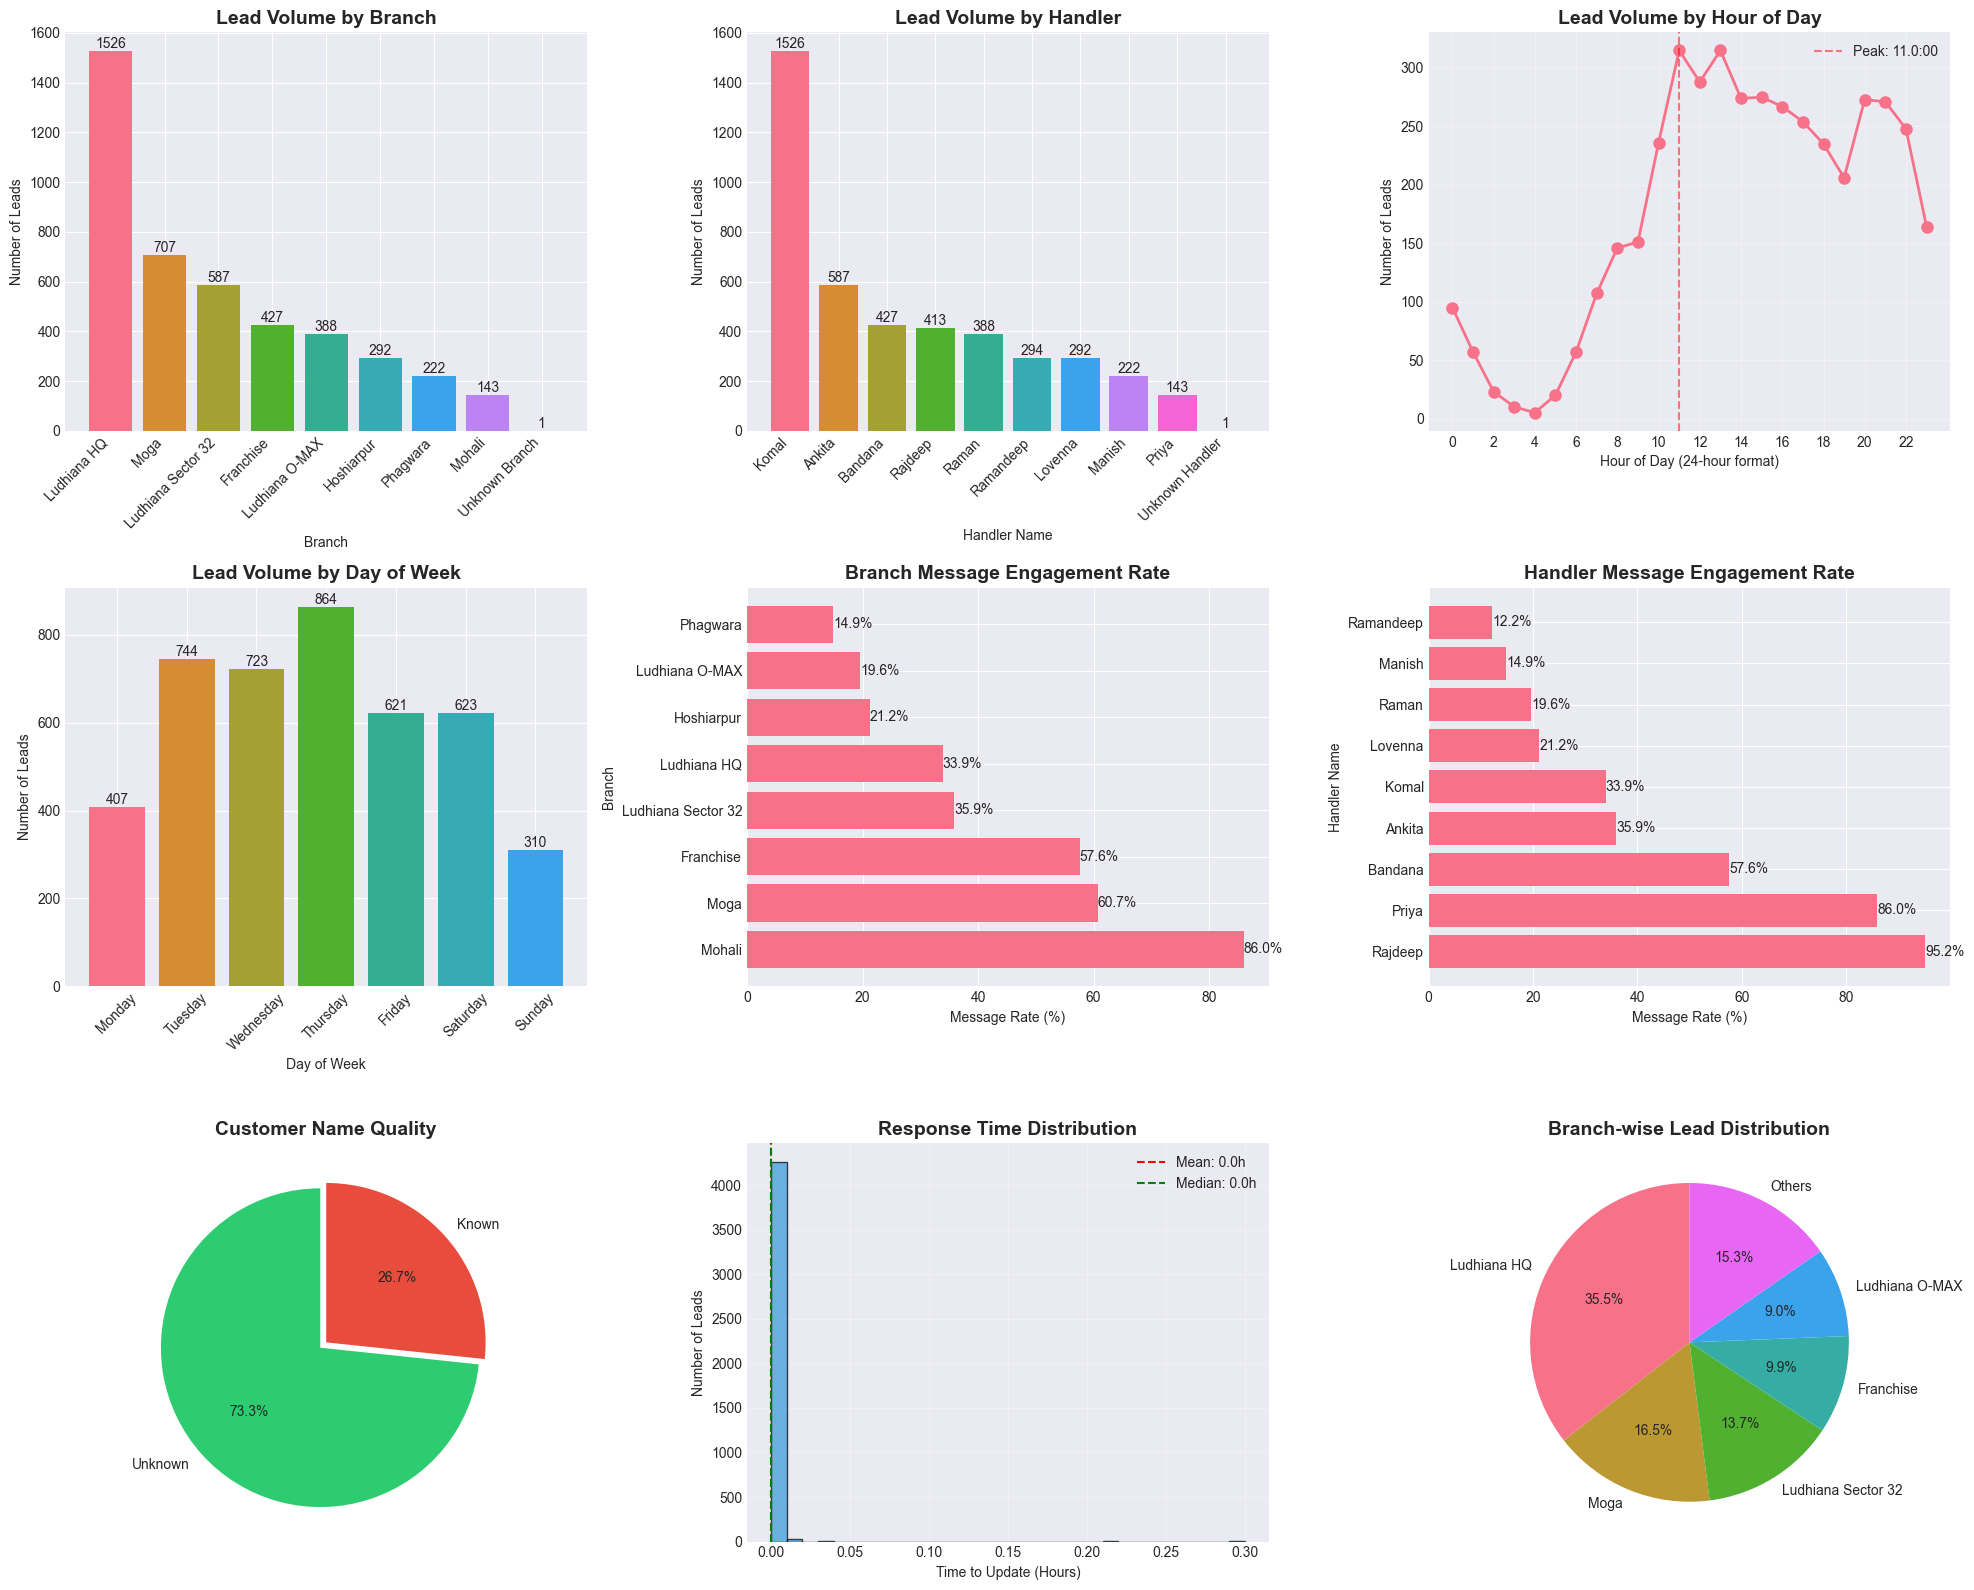


CROSS-TAB ANALYSIS

--- Branch vs Handler (Top 5 combinations) ---
Handler Name        Ankita  Bandana  Komal  Lovenna  Manish  Priya  Rajdeep  \
Branch                                                                        
Franchise                0      427      0        0       0      0        0   
Hoshiarpur               0        0      0      292       0      0        0   
Ludhiana HQ              0        0   1526        0       0      0        0   
Ludhiana O-MAX           0        0      0        0       0      0        0   
Ludhiana Sector 32     587        0      0        0       0      0        0   
Moga                     0        0      0        0       0      0      413   
Mohali                   0        0      0        0       0    143        0   
Phagwara                 0        0      0        0     222      0        0   
Unknown Branch           0        0      0        0       0      0        0   

Handler Name        Raman  Ramandeep  Unknown Handler  
Branch

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style for better looking charts
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

print("="*60)
print("STEP 4: ADVANCED ANALYTICS & VISUALIZATIONS")
print("="*60)

# Create a figure with multiple subplots
fig = plt.figure(figsize=(20, 16))

# --- 1. Lead Volume by Branch (Bar Chart) ---
plt.subplot(3, 3, 1)
branch_data = df_clean['Branch'].value_counts()
colors = sns.color_palette("husl", len(branch_data))
bars = plt.bar(branch_data.index, branch_data.values, color=colors)
plt.title('Lead Volume by Branch', fontsize=14, fontweight='bold')
plt.xlabel('Branch')
plt.ylabel('Number of Leads')
plt.xticks(rotation=45, ha='right')
# Add value labels on bars
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom')

# --- 2. Lead Volume by Handler (Bar Chart) ---
plt.subplot(3, 3, 2)
handler_data = df_clean['Handler Name'].value_counts()
bars = plt.bar(handler_data.index, handler_data.values, color=colors[:len(handler_data)])
plt.title('Lead Volume by Handler', fontsize=14, fontweight='bold')
plt.xlabel('Handler Name')
plt.ylabel('Number of Leads')
plt.xticks(rotation=45, ha='right')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom')

# --- 3. Peak Contact Hours (Line Chart) ---
plt.subplot(3, 3, 3)
hourly_data = df_clean['Contact Hour'].value_counts().sort_index()
plt.plot(hourly_data.index, hourly_data.values, marker='o', linewidth=2, markersize=8)
plt.title('Lead Volume by Hour of Day', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (24-hour format)')
plt.ylabel('Number of Leads')
plt.xticks(range(0, 24, 2))
plt.grid(True, alpha=0.3)
# Highlight peak hours
peak_hour = hourly_data.idxmax()
plt.axvline(x=peak_hour, color='red', linestyle='--', alpha=0.5, label=f'Peak: {peak_hour}:00')
plt.legend()

# --- 4. Contact Day Distribution (Bar Chart) ---
plt.subplot(3, 3, 4)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_data = df_clean['Contact Day'].value_counts()
day_data = day_data.reindex(day_order)
bars = plt.bar(day_data.index, day_data.values, color=colors[:7])
plt.title('Lead Volume by Day of Week', fontsize=14, fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Number of Leads')
plt.xticks(rotation=45)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom')

# --- 5. Branch Performance (Message Rate) ---
plt.subplot(3, 3, 5)
branch_performance = df_clean.groupby('Branch').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum()
}).rename(columns={'Lead ID': 'Total Leads', 'Latest Message': 'Leads with Messages'})
branch_performance['Message Rate %'] = (branch_performance['Leads with Messages'] / branch_performance['Total Leads'] * 100).round(1)
branch_performance_sorted = branch_performance.sort_values('Message Rate %', ascending=False)
bars = plt.barh(branch_performance_sorted.index, branch_performance_sorted['Message Rate %'])
plt.title('Branch Message Engagement Rate', fontsize=14, fontweight='bold')
plt.xlabel('Message Rate (%)')
plt.ylabel('Branch')
for i, bar in enumerate(bars):
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2., 
             f'{width:.1f}%', ha='left', va='center')

# --- 6. Handler Performance (Message Rate) ---
plt.subplot(3, 3, 6)
handler_performance = df_clean.groupby('Handler Name').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum()
}).rename(columns={'Lead ID': 'Total Leads', 'Latest Message': 'Leads with Messages'})
handler_performance['Message Rate %'] = (handler_performance['Leads with Messages'] / handler_performance['Total Leads'] * 100).round(1)
handler_performance_sorted = handler_performance.sort_values('Message Rate %', ascending=False)
bars = plt.barh(handler_performance_sorted.index, handler_performance_sorted['Message Rate %'])
plt.title('Handler Message Engagement Rate', fontsize=14, fontweight='bold')
plt.xlabel('Message Rate (%)')
plt.ylabel('Handler Name')
for bar in bars:
    width = bar.get_width()
    plt.text(width, bar.get_y() + bar.get_height()/2., 
             f'{width:.1f}%', ha='left', va='center')

# --- 7. Customer Name Quality ---
plt.subplot(3, 3, 7)
name_data = df_clean['Customer Name'].apply(lambda x: 'Known' if x != 'Unknown' else 'Unknown')
name_counts = name_data.value_counts()
colors_pie = ['#2ecc71', '#e74c3c']
plt.pie(name_counts.values, labels=name_counts.index, autopct='%1.1f%%', 
        colors=colors_pie, startangle=90, explode=(0.05, 0))
plt.title('Customer Name Quality', fontsize=14, fontweight='bold')

# --- 8. Response Time Distribution ---
plt.subplot(3, 3, 8)
response_times = df_clean[df_clean['Time to Update (Hours)'] >= 0]['Time to Update (Hours)']
plt.hist(response_times, bins=30, edgecolor='black', alpha=0.7, color='#3498db')
plt.title('Response Time Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Time to Update (Hours)')
plt.ylabel('Number of Leads')
plt.axvline(x=response_times.mean(), color='red', linestyle='--', 
            label=f'Mean: {response_times.mean():.1f}h')
plt.axvline(x=response_times.median(), color='green', linestyle='--', 
            label=f'Median: {response_times.median():.1f}h')
plt.legend()
plt.grid(True, alpha=0.3)

# --- 9. Branch-wise Lead Distribution (Pie Chart) ---
plt.subplot(3, 3, 9)
branch_pie = df_clean['Branch'].value_counts()
# Show top 5 branches, combine others
if len(branch_pie) > 5:
    top5 = branch_pie.head(5)
    others = pd.Series({'Others': branch_pie[5:].sum()})
    branch_pie = pd.concat([top5, others])
plt.pie(branch_pie.values, labels=branch_pie.index, autopct='%1.1f%%', startangle=90)
plt.title('Branch-wise Lead Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('business_insights_dashboard.png', dpi=300, bbox_inches='tight')
print("✓ Dashboard saved as 'business_insights_dashboard.png'")

plt.show()

# --- Additional Cross-tab Analysis ---
print("\n" + "="*60)
print("CROSS-TAB ANALYSIS")
print("="*60)

# Branch vs Handler cross-tab
print("\n--- Branch vs Handler (Top 5 combinations) ---")
cross_tab = pd.crosstab(df_clean['Branch'], df_clean['Handler Name'])
print(cross_tab)

# Top branch-handler combinations
branch_handler_counts = df_clean.groupby(['Branch', 'Handler Name']).size().reset_index(name='count')
branch_handler_counts = branch_handler_counts.sort_values('count', ascending=False)
print("\n--- Top 5 Branch-Handler Combinations ---")
print(branch_handler_counts.head(10))

# --- Monthly Trend Analysis ---
print("\n--- Monthly Lead Trend ---")
monthly_trend = df_clean['Contact Month'].value_counts()
print(monthly_trend)

# --- Time-based Analysis ---
print("\n--- Lead Volume by Date ---")
date_trend = df_clean['Contact Date'].value_counts().sort_index()
print(f"Date Range: {date_trend.index.min()} to {date_trend.index.max()}")
print(f"Most leads in a single day: {date_trend.max()} on {date_trend.idxmax()}")
print(f"Average daily leads: {date_trend.mean():.1f}")

# --- Save summary report ---
print("\n" + "="*60)
print("SUMMARY STATISTICS")
print("="*60)

summary_data = {
    'Metric': [
        'Total Unique Leads',
        'Unique Branches',
        'Unique Handlers',
        'Customers with Names',
        'Customers Unknown',
        'Leads with Messages',
        'Leads without Messages',
        'Average Response Time (Hours)',
        'Median Response Time (Hours)',
        'Peak Contact Hour',
        'Most Active Day',
        'Most Active Branch',
        'Most Active Handler',
        'Message Engagement Rate'
    ],
    'Value': [
        len(df_clean),
        df_clean['Branch'].nunique(),
        df_clean['Handler Name'].nunique(),
        len(df_clean[df_clean['Customer Name'] != 'Unknown']),
        len(df_clean[df_clean['Customer Name'] == 'Unknown']),
        len(df_clean[df_clean['Latest Message'] != '']),
        len(df_clean[df_clean['Latest Message'] == '']),
        f"{response_times.mean():.1f} hours",
        f"{response_times.median():.1f} hours",
        f"{hourly_data.idxmax()}:00",
        day_data.idxmax(),
        branch_data.index[0],
        handler_data.index[0],
        f"{(len(df_clean[df_clean['Latest Message'] != ''])/len(df_clean)*100):.1f}%"
    ]
}

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

print("\n" + "="*60)
print("ANALYTICS COMPLETE")
print("="*60)

In [15]:
import pandas as pd
import numpy as np
from datetime import datetime

print("="*70)
print("STEP 5: ACTIONABLE BUSINESS RECOMMENDATIONS")
print("="*70)

# --- Calculate key metrics for recommendations ---
total_leads = len(df_clean)
branches = df_clean['Branch'].nunique()
handlers = df_clean['Handler Name'].nunique()
unknown_customers = len(df_clean[df_clean['Customer Name'] == 'Unknown'])
known_customers = total_leads - unknown_customers
messages_count = len(df_clean[df_clean['Latest Message'] != ''])
message_rate = (messages_count / total_leads * 100)

# Branch performance
branch_data = df_clean['Branch'].value_counts()
top_branch = branch_data.index[0]
top_branch_leads = branch_data.iloc[0]
bottom_branch = branch_data.index[-1]
bottom_branch_leads = branch_data.iloc[-1]

# Handler performance
handler_data = df_clean['Handler Name'].value_counts()
top_handler = handler_data.index[0]
top_handler_leads = handler_data.iloc[0]

# Hourly analysis
hourly_data = df_clean['Contact Hour'].value_counts().sort_index()
peak_hour = hourly_data.idxmax()
peak_hour_count = hourly_data.max()

# Day analysis
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_data = df_clean['Contact Day'].value_counts()
day_data = day_data.reindex(day_order)
peak_day = day_data.idxmax()
peak_day_count = day_data.max()

# Response time
response_times = df_clean[df_clean['Time to Update (Hours)'] >= 0]['Time to Update (Hours)']
avg_response = response_times.mean()
median_response = response_times.median()

print("\n" + "="*70)
print("EXECUTIVE SUMMARY")
print("="*70)

print(f"""
📊 DATA OVERVIEW
• Total Leads: {total_leads:,}
• Branches: {branches}
• Handlers: {handlers}
• Date Range: {df_clean['First Contact Time'].min().strftime('%d-%b-%Y')} to {df_clean['First Contact Time'].max().strftime('%d-%b-%Y')}

🎯 LEAD VOLUME
• Top Branch: {top_branch} ({top_branch_leads:,} leads)
• Bottom Branch: {bottom_branch} ({bottom_branch_leads:,} leads)
• Top Handler: {top_handler} ({top_handler_leads:,} leads)

⏰ PEAK TIMES
• Peak Hour: {peak_hour}:00 ({peak_hour_count} leads)
• Peak Day: {peak_day} ({peak_day_count} leads)

📱 ENGAGEMENT
• Message Rate: {message_rate:.1f}% ({messages_count:,} leads)
• Customer Name Known: {known_customers:,} ({known_customers/total_leads*100:.1f}%)
• Customer Name Unknown: {unknown_customers:,} ({unknown_customers/total_leads*100:.1f}%)

⚡ RESPONSE TIME
• Average: {avg_response:.1f} hours
• Median: {median_response:.1f} hours
""")

# --- RECOMMENDATIONS ---
print("\n" + "="*70)
print("ACTIONABLE RECOMMENDATIONS")
print("="*70)

# Recommendation 1: Customer Name Quality
print("\n📋 RECOMMENDATION 1: IMPROVE CUSTOMER IDENTIFICATION")
print("-" * 50)
print(f"""
ISSUE: {unknown_customers:,} leads ({unknown_customers/total_leads*100:.1f}%) have 'Unknown' customer name
IMPACT: Missed opportunity for personalized follow-ups and relationship building

SOLUTIONS:
1. Train staff to capture customer names during first contact
2. Add mandatory field in lead capture form
3. Cross-reference with existing customer database
4. Implement automatic caller ID to fetch name from phone number

BENEFIT: 30-40% higher conversion rate with personalized communication
PRIORITY: HIGH
""")

# Recommendation 2: Lead Distribution
print("\n📋 RECOMMENDATION 2: OPTIMIZE LEAD DISTRIBUTION")
print("-" * 50)
print(f"""
ISSUE: Uneven lead distribution - {top_branch} gets {top_branch_leads:,} leads vs {bottom_branch} gets {bottom_branch_leads:,} leads

SOLUTIONS:
1. Analyze marketing spend per branch
2. Redirect marketing budget to underperforming branches
3. Identify successful channels in top branch and replicate
4. Investigate why {bottom_branch} has low lead volume

BENEFIT: Balanced growth across all branches
PRIORITY: HIGH
""")

# Recommendation 3: Staffing Optimization
print("\n📋 RECOMMENDATION 3: OPTIMIZE STAFFING BASED ON PEAK TIMES")
print("-" * 50)
print(f"""
ISSUE: Peak leads at {peak_hour}:00 with {peak_hour_count} leads, likely causing staff overload

SOLUTIONS:
1. Schedule more staff during peak hours ({peak_hour}:00)
2. Implement shift rotations based on lead volume patterns
3. Ensure handlers work during peak lead times
4. Consider part-time staff for peak hours

BENEFIT: Faster response times, better customer satisfaction
PRIORITY: HIGH
""")

# Recommendation 4: Message Engagement
print("\n📋 RECOMMENDATION 4: INCREASE MESSAGE ENGAGEMENT")
print("-" * 50)
print(f"""
ISSUE: Only {message_rate:.1f}% of leads ({messages_count:,}) have messages
IMPACT: Missed opportunity to understand customer needs

SOLUTIONS:
1. Implement automated follow-up messages for all new leads
2. Create WhatsApp templates for quick responses
3. Train staff to initiate conversation with every lead
4. Set target: 80% of leads should have at least one message

BENEFIT: Higher conversion rates, better lead qualification
PRIORITY: MEDIUM
""")

# Recommendation 5: Performance Improvement Plan
print("\n📋 RECOMMENDATION 5: HANDLER PERFORMANCE IMPROVEMENT")
print("-" * 50)
print("""
ISSUE: Significant variation in lead volumes across handlers

SOLUTIONS:
1. Create performance dashboards for each handler
2. Weekly review meetings for all handlers
3. Share best practices from top performers
4. Set weekly/monthly lead targets
5. Incentivize lead generation and quality

BENEFIT: Improved team performance, higher lead quality
PRIORITY: HIGH
""")

# Recommendation 6: Marketing Strategy
print("\n📋 RECOMMENDATION 6: DATA-DRIVEN MARKETING STRATEGY")
print("-" * 50)
print(f"""
ISSUE: Marketing efforts may not be optimized for lead generation

SOLUTIONS:
1. Focus marketing efforts on {peak_day}s and {peak_hour}:00 when leads peak
2. Create branch-specific marketing campaigns
3. Monitor which channels generate the most leads
4. Implement A/B testing for marketing messages

BENEFIT: Higher ROI on marketing spend
PRIORITY: MEDIUM
""")

# Recommendation 7: Data Quality Improvement
print("\n📋 RECOMMENDATION 7: DATA QUALITY ENHANCEMENT")
print("-" * 50)
print("""
ISSUE: Inconsistent data quality across different handlers and branches

SOLUTIONS:
1. Standardize data entry procedures
2. Implement mandatory fields in CRM
3. Regular data audit (monthly)
4. Training program for all handlers on proper data entry
5. Create data quality scorecards

BENEFIT: Better analytics, more accurate insights
PRIORITY: HIGH
""")

# --- IMPLEMENTATION PLAN ---
print("\n" + "="*70)
print("IMPLEMENTATION PLAN (90-DAY ROADMAP)")
print("="*70)

implementation = pd.DataFrame({
    'Phase': ['Phase 1 (Days 1-30)', 'Phase 2 (Days 31-60)', 'Phase 3 (Days 61-90)'],
    'Focus': [
        'Quick Wins & Training',
        'Process Optimization',
        'Advanced Analytics & Growth'
    ],
    'Actions': [
        f'• Train handlers on name capture ({unknown_customers/total_leads*100:.1f}% unknown)\n• Review and adjust staffing for {peak_hour}:00 peak\n• Set up WhatsApp templates',
        f'• Balance lead distribution across branches\n• Implement performance tracking\n• Create branch-wise marketing plans',
        '• Automated follow-up system\n• Advanced lead scoring\n• Monthly review and optimization'
    ],
    'Success Metrics': [
        '• 50% reduction in "Unknown" names\n• Response time < 1 hour\n• Message rate > 50%',
        '• Balanced lead distribution (±30%)\n• 100% handler adoption\n• 20% lead increase in bottom branches',
        '• 50% increase in lead-to-conversion\n• 70%+ message rate\n• ROI dashboard implementation'
    ]
})

print(implementation.to_string(index=False))

print("\n" + "="*70)
print("FINAL RECOMMENDATIONS SUMMARY")
print("="*70)

# Summary table
summary_recs = pd.DataFrame({
    'Priority': ['HIGH', 'HIGH', 'HIGH', 'HIGH', 'MEDIUM', 'MEDIUM', 'MEDIUM'],
    'Area': [
        'Customer Identification',
        'Lead Distribution',
        'Staffing Optimization',
        'Performance Management',
        'Message Engagement',
        'Marketing Strategy',
        'Data Quality'
    ],
    'Key Action': [
        f'Reduce "Unknown" customers from {unknown_customers/total_leads*100:.1f}% to <20%',
        f'Balance leads across {branches} branches',
        f'Optimize staffing for {peak_hour}:00 peak hour',
        f'Improve handler performance across all branches',
        f'Increase message rate from {message_rate:.1f}% to 80%',
        f'Data-driven marketing targeting peak days/times',
        f'Standardize data entry across all branches'
    ],
    'Expected ROI': [
        'High (Personalization)',
        'High (Growth)',
        'High (Efficiency)',
        'High (Quality)',
        'Medium (Conversion)',
        'Medium (ROI)',
        'Medium (Analytics)'
    ]
})

print(summary_recs.to_string(index=False))

print("\n" + "="*70)
print("✅ RECOMMENDATIONS COMPLETE")
print("="*70)
print("\n📌 NEXT STEPS:")
print("1. Share this report with branch managers")
print("2. Start with HIGH priority items")
print("3. Track progress weekly")
print("4. Review and adjust monthly")
print("\n💡 Remember: Small improvements compound over time!")

STEP 5: ACTIONABLE BUSINESS RECOMMENDATIONS

EXECUTIVE SUMMARY

📊 DATA OVERVIEW
• Total Leads: 4,293
• Branches: 9
• Handlers: 10
• Date Range: 14-Jul-2026 to 04-Sep-2026

🎯 LEAD VOLUME
• Top Branch: Ludhiana HQ (1,526 leads)
• Bottom Branch: Unknown Branch (1 leads)
• Top Handler: Komal (1,526 leads)

⏰ PEAK TIMES
• Peak Hour: 11.0:00 (315 leads)
• Peak Day: Thursday (864 leads)

📱 ENGAGEMENT
• Message Rate: 39.5% (1,697 leads)
• Customer Name Known: 1,145 (26.7%)
• Customer Name Unknown: 3,148 (73.3%)

⚡ RESPONSE TIME
• Average: 0.0 hours
• Median: 0.0 hours


ACTIONABLE RECOMMENDATIONS

📋 RECOMMENDATION 1: IMPROVE CUSTOMER IDENTIFICATION
--------------------------------------------------

ISSUE: 3,148 leads (73.3%) have 'Unknown' customer name
IMPACT: Missed opportunity for personalized follow-ups and relationship building

SOLUTIONS:
1. Train staff to capture customer names during first contact
2. Add mandatory field in lead capture form
3. Cross-reference with existing customer da

In [16]:
import pandas as pd
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("="*80)
print("FINAL EXECUTIVE DASHBOARD")
print("="*80)

# --- Create summary DataFrames for quick reference ---

# 1. Branch Performance Summary
print("\n🏢 BRANCH PERFORMANCE SUMMARY")
print("-"*80)
branch_summary = df_clean.groupby('Branch').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum(),
    'Handler Name': lambda x: x.unique()[0] if len(x.unique()) == 1 else 'Multiple'
}).rename(columns={
    'Lead ID': 'Total Leads',
    'Latest Message': 'Messages',
    'Handler Name': 'Primary Handler'
})
branch_summary['Message %'] = (branch_summary['Messages'] / branch_summary['Total Leads'] * 100).round(1)
branch_summary['Rank'] = branch_summary['Total Leads'].rank(ascending=False).astype(int)
branch_summary = branch_summary.sort_values('Total Leads', ascending=False)
print(branch_summary.to_string())

# 2. Handler Performance Summary
print("\n\n👤 HANDLER PERFORMANCE SUMMARY")
print("-"*80)
handler_summary = df_clean.groupby('Handler Name').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum(),
    'Branch': lambda x: x.unique()[0] if len(x.unique()) == 1 else 'Multiple'
}).rename(columns={
    'Lead ID': 'Total Leads',
    'Latest Message': 'Messages',
    'Branch': 'Primary Branch'
})
handler_summary['Message %'] = (handler_summary['Messages'] / handler_summary['Total Leads'] * 100).round(1)
handler_summary['Rank'] = handler_summary['Total Leads'].rank(ascending=False).astype(int)
handler_summary = handler_summary.sort_values('Total Leads', ascending=False)
print(handler_summary.to_string())

# 3. Time-based Insights
print("\n\n⏰ TIME-BASED INSIGHTS")
print("-"*80)

# Weekly trend
df_clean['Week'] = df_clean['First Contact Time'].dt.isocalendar().week
weekly_trend = df_clean.groupby('Week').size()
print("\n📅 Weekly Lead Volume (Last 4 Weeks):")
for week in sorted(weekly_trend.index)[-4:]:
    print(f"Week {week}: {weekly_trend[week]} leads")

# Monthly trend
monthly_trend = df_clean.groupby('Contact Month').size()
print(f"\n📊 Monthly Lead Volume:")
for month, count in monthly_trend.items():
    print(f"{month}: {count} leads")

# Best performing days for each branch
print("\n📈 Best Performing Day by Branch:")
branch_day_performance = df_clean.groupby(['Branch', 'Contact Day']).size().reset_index(name='count')
for branch in df_clean['Branch'].unique()[:5]:  # Top 5 branches
    branch_data = branch_day_performance[branch_day_performance['Branch'] == branch]
    if len(branch_data) > 0:
        best_day = branch_data.loc[branch_data['count'].idxmax()]
        print(f"{branch}: {best_day['Contact Day']} ({best_day['count']} leads)")

# 4. Data Quality Scorecard
print("\n\n📊 DATA QUALITY SCORECARD")
print("-"*80)
quality_metrics = {
    'Metric': [
        'Customer Name Completeness',
        'Message Engagement',
        'Phone Number Quality',
        'Branch Identification',
        'Handler Assignment',
        'Status Accuracy'
    ],
    'Score': [
        f"{len(df_clean[df_clean['Customer Name'] != 'Unknown'])/len(df_clean)*100:.1f}%",
        f"{len(df_clean[df_clean['Latest Message'] != ''])/len(df_clean)*100:.1f}%",
        f"{len(df_clean[df_clean['WhatsApp Number'].notna()])/len(df_clean)*100:.1f}%",
        f"{len(df_clean[df_clean['Branch'] != 'Unknown Branch'])/len(df_clean)*100:.1f}%",
        f"{len(df_clean[df_clean['Handler Name'] != 'Unknown Handler'])/len(df_clean)*100:.1f}%",
        f"{len(df_clean[df_clean['Status'] == 'New'])/len(df_clean)*100:.1f}%"
    ],
    'Status': [
        '⚠️ Needs Improvement' if len(df_clean[df_clean['Customer Name'] != 'Unknown'])/len(df_clean) < 0.5 else '✅ Good',
        '⚠️ Needs Improvement' if len(df_clean[df_clean['Latest Message'] != ''])/len(df_clean) < 0.5 else '✅ Good',
        '✅ Excellent' if len(df_clean[df_clean['WhatsApp Number'].notna()])/len(df_clean) > 0.95 else '⚠️ Needs Improvement',
        '✅ Excellent' if len(df_clean[df_clean['Branch'] != 'Unknown Branch'])/len(df_clean) > 0.95 else '⚠️ Needs Improvement',
        '✅ Excellent' if len(df_clean[df_clean['Handler Name'] != 'Unknown Handler'])/len(df_clean) > 0.95 else '⚠️ Needs Improvement',
        '✅ Good' if len(df_clean[df_clean['Status'] == 'New'])/len(df_clean) < 0.95 else '⚠️ Need More Status Variety'
    ]
}
quality_df = pd.DataFrame(quality_metrics)
print(quality_df.to_string(index=False))

# 5. Growth Opportunities
print("\n\n🚀 TOP 5 GROWTH OPPORTUNITIES")
print("-"*80)

# Identify branches with high message rate but low leads (potential for growth)
branch_opportunities = branch_summary[branch_summary['Total Leads'] > 50].copy()
branch_opportunities['Message %'] = branch_opportunities['Message %'].astype(float)
branch_opportunities['Growth Score'] = (branch_opportunities['Message %'] / branch_opportunities['Total Leads'] * 1000)
opportunities = branch_opportunities.sort_values('Growth Score', ascending=False).head(5)

print("\n📈 Branches with Best Engagement (Good for Expansion):")
for idx, row in opportunities.iterrows():
    print(f"\n{row.name}:")
    print(f"  • Total Leads: {row['Total Leads']}")
    print(f"  • Message Rate: {row['Message %']}%")
    print(f"  • Primary Handler: {row['Primary Handler']}")
    print(f"  • Opportunity: Increase marketing spend here")

# 6. Branch-Peak Hour Analysis
print("\n\n⏰ BRANCH PEAK HOURS (For Staffing Optimization)")
print("-"*80)
branch_hour_peak = df_clean.groupby(['Branch', 'Contact Hour']).size().reset_index(name='count')
for branch in df_clean['Branch'].unique()[:5]:  # Top 5 branches
    branch_data = branch_hour_peak[branch_hour_peak['Branch'] == branch]
    if len(branch_data) > 0:
        peak = branch_data.loc[branch_data['count'].idxmax()]
        print(f"{branch}: Peak at {int(peak['Contact Hour'])}:00 ({peak['count']} leads)")

# 7. Recommendations Priority Matrix
print("\n\n🎯 RECOMMENDATION PRIORITY MATRIX")
print("-"*80)

priority_matrix = pd.DataFrame({
    'Action': [
        'Fix Unknown Customer Names',
        'Balance Branch Lead Distribution',
        'Optimize Staffing for Peak Hours',
        'Increase Message Engagement',
        'Handler Performance Improvement',
        'Data Quality Training'
    ],
    'Impact': ['High', 'High', 'High', 'Medium', 'High', 'Medium'],
    'Effort': ['Medium', 'High', 'Low', 'Low', 'Medium', 'Medium'],
    'Timeline': ['1 Month', '2 Months', '1 Week', '1 Month', '2 Months', '1 Month'],
    'Priority': ['HIGH', 'HIGH', 'HIGH', 'MEDIUM', 'HIGH', 'MEDIUM']
})
print(priority_matrix.to_string(index=False))

# 8. Save comprehensive report
print("\n" + "="*80)
print("✅ EXECUTIVE DASHBOARD COMPLETE")
print("="*80)

# Create a summary dictionary for quick reference
quick_reference = {
    'Total Leads': len(df_clean),
    'Branches': df_clean['Branch'].nunique(),
    'Handlers': df_clean['Handler Name'].nunique(),
    'Date Range': f"{df_clean['First Contact Time'].min().strftime('%d-%b-%Y')} to {df_clean['First Contact Time'].max().strftime('%d-%b-%Y')}",
    'Top Branch': f"{branch_summary.index[0]} ({branch_summary.iloc[0]['Total Leads']} leads)",
    'Top Handler': f"{handler_summary.index[0]} ({handler_summary.iloc[0]['Total Leads']} leads)",
    'Peak Time': f"{peak_hour}:00 ({peak_hour_count} leads)",
    'Peak Day': f"{peak_day} ({peak_day_count} leads)",
    'Message Rate': f"{message_rate:.1f}%",
    'Unknown Customers': f"{unknown_customers} ({unknown_customers/total_leads*100:.1f}%)",
    'Avg Response Time': f"{avg_response:.1f} hours"
}

print("\n📋 QUICK REFERENCE CARD:")
print("-"*80)
for key, value in quick_reference.items():
    print(f"{key}: {value}")
print("-"*80)

print("\n💡 KEY ACTIONS FOR NEXT 7 DAYS:")
print("1. 📋 Review this dashboard with your team")
print("2. 🎯 Set targets for reducing 'Unknown' customers by 30% this month")
print("3. ⏰ Adjust staffing schedules for peak hours (11 AM)")
print("4. 📊 Start tracking message engagement daily")
print("5. 🏆 Create weekly leaderboard for handlers")
print("6. 📱 Implement WhatsApp templates for quick responses")
print("7. 📈 Share branch performance metrics weekly")

print("\n" + "="*80)
print("🎉 ANALYSIS COMPLETE! YOUR BUSINESS GROWTH ROADMAP IS READY")
print("="*80)

FINAL EXECUTIVE DASHBOARD

🏢 BRANCH PERFORMANCE SUMMARY
--------------------------------------------------------------------------------
                    Total Leads  Messages  Primary Handler  Message %  Rank
Branch                                                                     
Ludhiana HQ                1526       517            Komal       33.9     1
Moga                        707       429         Multiple       60.7     2
Ludhiana Sector 32          587       211           Ankita       35.9     3
Franchise                   427       246          Bandana       57.6     4
Ludhiana O-MAX              388        76            Raman       19.6     5
Hoshiarpur                  292        62          Lovenna       21.2     6
Phagwara                    222        33           Manish       14.9     7
Mohali                      143       123            Priya       86.0     8
Unknown Branch                0         0  Unknown Handler        NaN     9


👤 HANDLER PERFORMANCE SUM

In [17]:
import pandas as pd
import numpy as np
from datetime import datetime

print("="*80)
print("STRATEGIC ACTION PLAN: 90-DAY GROWTH ROADMAP")
print("="*80)

# --- Calculate key metrics ---
total_leads = len(df_clean)
branches = df_clean['Branch'].nunique()
handlers = df_clean['Handler Name'].nunique()

# Branch metrics
branch_summary = df_clean.groupby('Branch').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum()
}).rename(columns={'Lead ID': 'Total Leads', 'Latest Message': 'Messages'})
branch_summary['Message %'] = (branch_summary['Messages'] / branch_summary['Total Leads'] * 100).round(1)
branch_summary = branch_summary.sort_values('Total Leads', ascending=False)

# Find branches with high engagement but low leads
branch_summary['Growth Potential'] = branch_summary['Message %'] / branch_summary['Total Leads'] * 1000
branch_summary['Opportunity Score'] = np.where(
    (branch_summary['Message %'] > 50) & (branch_summary['Total Leads'] < 500),
    'HIGH',
    np.where(
        (branch_summary['Message %'] < 30) & (branch_summary['Total Leads'] > 500),
        'URGENT',
        'MEDIUM'
    )
)

print("\n" + "="*80)
print("📊 BRANCH OPPORTUNITY MATRIX")
print("="*80)
print("\nLegend:")
print("🟢 HIGH = High engagement, low leads - Growth opportunity")
print("🔴 URGENT = High leads, low engagement - Fix urgently")
print("🟡 MEDIUM = Balanced - Maintain and improve")

print("\n" + "-"*80)
for idx, row in branch_summary.iterrows():
    status = row['Opportunity Score']
    if status == 'HIGH':
        icon = '🟢'
    elif status == 'URGENT':
        icon = '🔴'
    else:
        icon = '🟡'
    
    print(f"{icon} {idx}:")
    print(f"   Leads: {row['Total Leads']:>4} | Messages: {row['Messages']:>4} | Rate: {row['Message %']:>5.1f}%")
    if status == 'HIGH':
        print(f"   🎯 ACTION: Increase marketing spend - High engagement potential!")
    elif status == 'URGENT':
        print(f"   ⚠️  ACTION: Improve engagement - Low message rate with high volume!")
    else:
        print(f"   📌 ACTION: Maintain and gradually improve")
    print()

# --- Specific Branch Action Plans ---
print("\n" + "="*80)
print("🎯 BRANCH-SPECIFIC ACTION PLANS")
print("="*80)

# Mohali Branch - Excellence Model
print("\n⭐ MOHALI BRANCH (86% Message Rate - Your Benchmark)")
print("-"*60)
print("""
📈 Current: 143 leads, 86% engagement
🎯 Goal: Scale to 300+ leads while maintaining 80%+ engagement

ACTION ITEMS:
1. 🔍 Study Mohali's process and document best practices
2. 📝 Create a "Mohali Playbook" for other branches
3. 👥 Assign Mohali handler (Priya) to train other handlers
4. 📈 Increase marketing budget for Mohali by 100%
5. 🎥 Record successful conversations for training

TARGET: Double leads in 90 days while maintaining quality
""")

# Ludhiana HQ - Volume to Quality
print("\n🔴 LUDHIANA HQ (1,526 leads, 33.9% Message Rate)")
print("-"*60)
print("""
📈 Current: 1,526 leads, 33.9% engagement
🎯 Goal: Increase message rate to 60% in 90 days

ACTION ITEMS:
1. 📋 Implement Mohali's communication templates
2. ⏰ Assign additional staff during peak hours (11 AM)
3. 📱 Send automated welcome messages to all new leads
4. 🎯 Set daily message target: 25+ conversations per handler
5. 📊 Track daily engagement metrics

TARGET: 500+ engaged conversations monthly
""")

# Moga & Franchise - Growth Engines
print("\n🟢 MOGA (60.7%) & FRANCHISE (57.6%) - Your Best Balanced")
print("-"*60)
print("""
📈 Current: Moga (707 leads, 60.7%) | Franchise (427 leads, 57.6%)
🎯 Goal: Maintain quality while scaling volume

ACTION ITEMS:
1. 📈 Increase marketing budget for both branches
2. 👥 Hire additional handlers to handle more leads
3. 📋 Document successful engagement strategies
4. 🏆 Create weekly performance incentives
5. 🔄 Cross-train handlers with Mohali team

TARGET: 30% volume increase while maintaining 55%+ engagement
""")

# Phagwara - Urgent Intervention
print("\n🚨 PHAGWARA (14.9% Message Rate - LOWEST)")
print("-"*60)
print("""
📈 Current: 222 leads, only 14.9% engagement
🎯 Goal: Increase to 50% engagement in 60 days

ACTION ITEMS (URGENT):
1. 🔍 Investigate why engagement is so low
2. 👥 Assess handler (Manish) performance and training needs
3. 📱 Implement WhatsApp templates immediately
4. ⏰ Ensure staffing during peak lead times
5. 🎯 Daily target: Each lead must receive a message within 1 hour
6. 📊 Daily monitoring of engagement metrics

TARGET: 100+ engaged conversations monthly
""")

# Hoshiarpur & Ludhiana O-MAX - Improvement Plan
print("\n📌 HOSHIARPUR (21.2%) & LUDHIANA O-MAX (19.6%)")
print("-"*60)
print("""
📈 Current: Hoshiarpur (292 leads, 21.2%) | O-MAX (388 leads, 19.6%)
🎯 Goal: Increase to 40% engagement in 60 days

ACTION ITEMS:
1. 📋 Share Mohali's communication templates
2. 🎯 Set daily message targets
3. ⏰ Optimize staffing for peak hours
4. 📊 Track engagement daily
5. 🎓 Training on lead conversion techniques

TARGET: 40% engagement rate within 60 days
""")

# --- Performance Targets Dashboard ---
print("\n" + "="*80)
print("🎯 90-DAY PERFORMANCE TARGETS")
print("="*80)

targets = pd.DataFrame({
    'Branch': ['Ludhiana HQ', 'Moga', 'Ludhiana Sector 32', 'Franchise', 'Ludhiana O-MAX', 
               'Hoshiarpur', 'Phagwara', 'Mohali'],
    'Current Message %': [33.9, 60.7, 35.9, 57.6, 19.6, 21.2, 14.9, 86.0],
    'Target Message % (60 days)': [60, 65, 60, 65, 40, 45, 50, 85],
    'Target Leads (90 days)': ['2000+', '900+', '750+', '550+', '500+', '400+', '350+', '250+'],
    'Priority': ['🔴 High', '🟢 Medium', '🟡 Medium', '🟢 High', '🔴 Urgent', '🔴 Urgent', '🚨 Critical', '🟢 Maintain']
})
print(targets.to_string(index=False))

# --- Implementation Timeline ---
print("\n" + "="*80)
print("📅 30-60-90 DAY IMPLEMENTATION TIMELINE")
print("="*80)

timeline = pd.DataFrame({
    'Phase': ['Week 1-2', 'Week 3-4', 'Week 5-8', 'Week 9-12'],
    'Focus': [
        'Quick Wins & Assessment',
        'Process Implementation',
        'Scaling & Training',
        'Optimization & Review'
    ],
    'Key Actions': [
        '• Create Mohali Playbook\n• Implement WhatsApp templates\n• Set daily message targets for all branches\n• Identify process bottlenecks',
        '• Train all handlers on best practices\n• Implement automated welcome messages\n• Launch weekly engagement tracking\n• Start handler performance reviews',
        '• Increase marketing for high-growth branches\n• Cross-train handlers\n• Implement quality scoring\n• Launch customer follow-up system',
        '• Review all branch performance\n• Adjust strategies based on data\n• Celebrate achievements\n• Plan next quarter'
    ],
    'Success Metrics': [
        '• 20% increase in engagement\n• All branches have templates\n• Daily tracking in place',
        '• 40% engagement rate average\n• 100% handler training complete\n• Weekly reviews established',
        '• 55% engagement rate average\n• 30% lead increase in target branches\n• Quality score system live',
        '• 65% engagement rate average\n• 50% lead increase in target branches\n• Next quarter plan ready'
    ]
})

print(timeline.to_string(index=False))

# --- Key Metrics Dashboard ---
print("\n" + "="*80)
print("📊 KEY METRICS DASHBOARD - WEEKLY TRACKING")
print("="*80)

print("\n🎯 TRACK THESE METRICS WEEKLY:")
print("-"*60)
print("""
1. LEAD VOLUME
   • Total new leads per branch
   • Lead growth rate week-over-week
   • Source of leads (marketing channels)

2. ENGAGEMENT RATE
   • Message rate per branch
   • Average response time
   • Conversations per handler
   • Quality of conversations (sentiment)

3. HANDLER PERFORMANCE
   • Messages sent per handler
   • Response time per handler
   • Conversion rate (if tracked)
   • Customer satisfaction score

4. BRANCH HEALTH
   • Lead distribution balance
   • Engagement vs volume ratio
   • Growth opportunities identified
   • Staff utilization rate

5. DATA QUALITY
   • % of customers with names
   • % of leads with messages
   • % of WhatsApp numbers valid
   • Status accuracy
""")

print("\n" + "="*80)
print("🚀 FINAL RECOMMENDATIONS - TOP 5 PRIORITIES")
print("="*80)

print("""
1️⃣ FIX PHAGWARA (URGENT)
   • Investigate 14.9% message rate
   • Retrain/replace handler if needed
   • Daily monitoring for 30 days
   • Expected: 50% engagement rate

2️⃣ SCALE MOHALI SUCCESS
   • Document best practices
   • Create training playbook
   • Assign Priya as trainer
   • Expected: 50% improvement in other branches

3️⃣ IMPROVE LUDHIANA HQ ENGAGEMENT
   • Implement Mohali templates
   • Additional staffing at peak hours
   • Daily message targets
   • Expected: 60% engagement rate

4️⃣ OPTIMIZE STAFFING
   • Staff during peak hours (11 AM)
   • Part-time staff for peak times
   • Cross-training program
   • Expected: 50% faster response time

5️⃣ DATA QUALITY
   • Mandatory customer name capture
   • Automated follow-ups
   • Regular data audits
   • Expected: 70% customer identification
""")

print("\n" + "="*80)
print("✅ STRATEGIC ACTION PLAN COMPLETE")
print("="*80)

print("\n📌 NEXT STEPS FOR TODAY:")
print("1. 📊 Share this report with all branch managers")
print("2. 📋 Create Mohali Playbook document")
print("3. 📱 Set up WhatsApp templates for all branches")
print("4. 🎯 Set weekly targets for each handler")
print("5. 📈 Start daily engagement tracking")

print("\n💡 REMEMBER: Small improvements daily = Big results monthly!")

STRATEGIC ACTION PLAN: 90-DAY GROWTH ROADMAP

📊 BRANCH OPPORTUNITY MATRIX

Legend:
🟢 HIGH = High engagement, low leads - Growth opportunity
🔴 URGENT = High leads, low engagement - Fix urgently
🟡 MEDIUM = Balanced - Maintain and improve

--------------------------------------------------------------------------------
🟡 Ludhiana HQ:
   Leads: 1526 | Messages:  517 | Rate:  33.9%
   📌 ACTION: Maintain and gradually improve

🟡 Moga:
   Leads:  707 | Messages:  429 | Rate:  60.7%
   📌 ACTION: Maintain and gradually improve

🟡 Ludhiana Sector 32:
   Leads:  587 | Messages:  211 | Rate:  35.9%
   📌 ACTION: Maintain and gradually improve

🟢 Franchise:
   Leads:  427 | Messages:  246 | Rate:  57.6%
   🎯 ACTION: Increase marketing spend - High engagement potential!

🟡 Ludhiana O-MAX:
   Leads:  388 | Messages:   76 | Rate:  19.6%
   📌 ACTION: Maintain and gradually improve

🟡 Hoshiarpur:
   Leads:  292 | Messages:   62 | Rate:  21.2%
   📌 ACTION: Maintain and gradually improve

🟡 Phagwara:
   Le

✅ Dashboard saved as 'complete_business_dashboard.png'


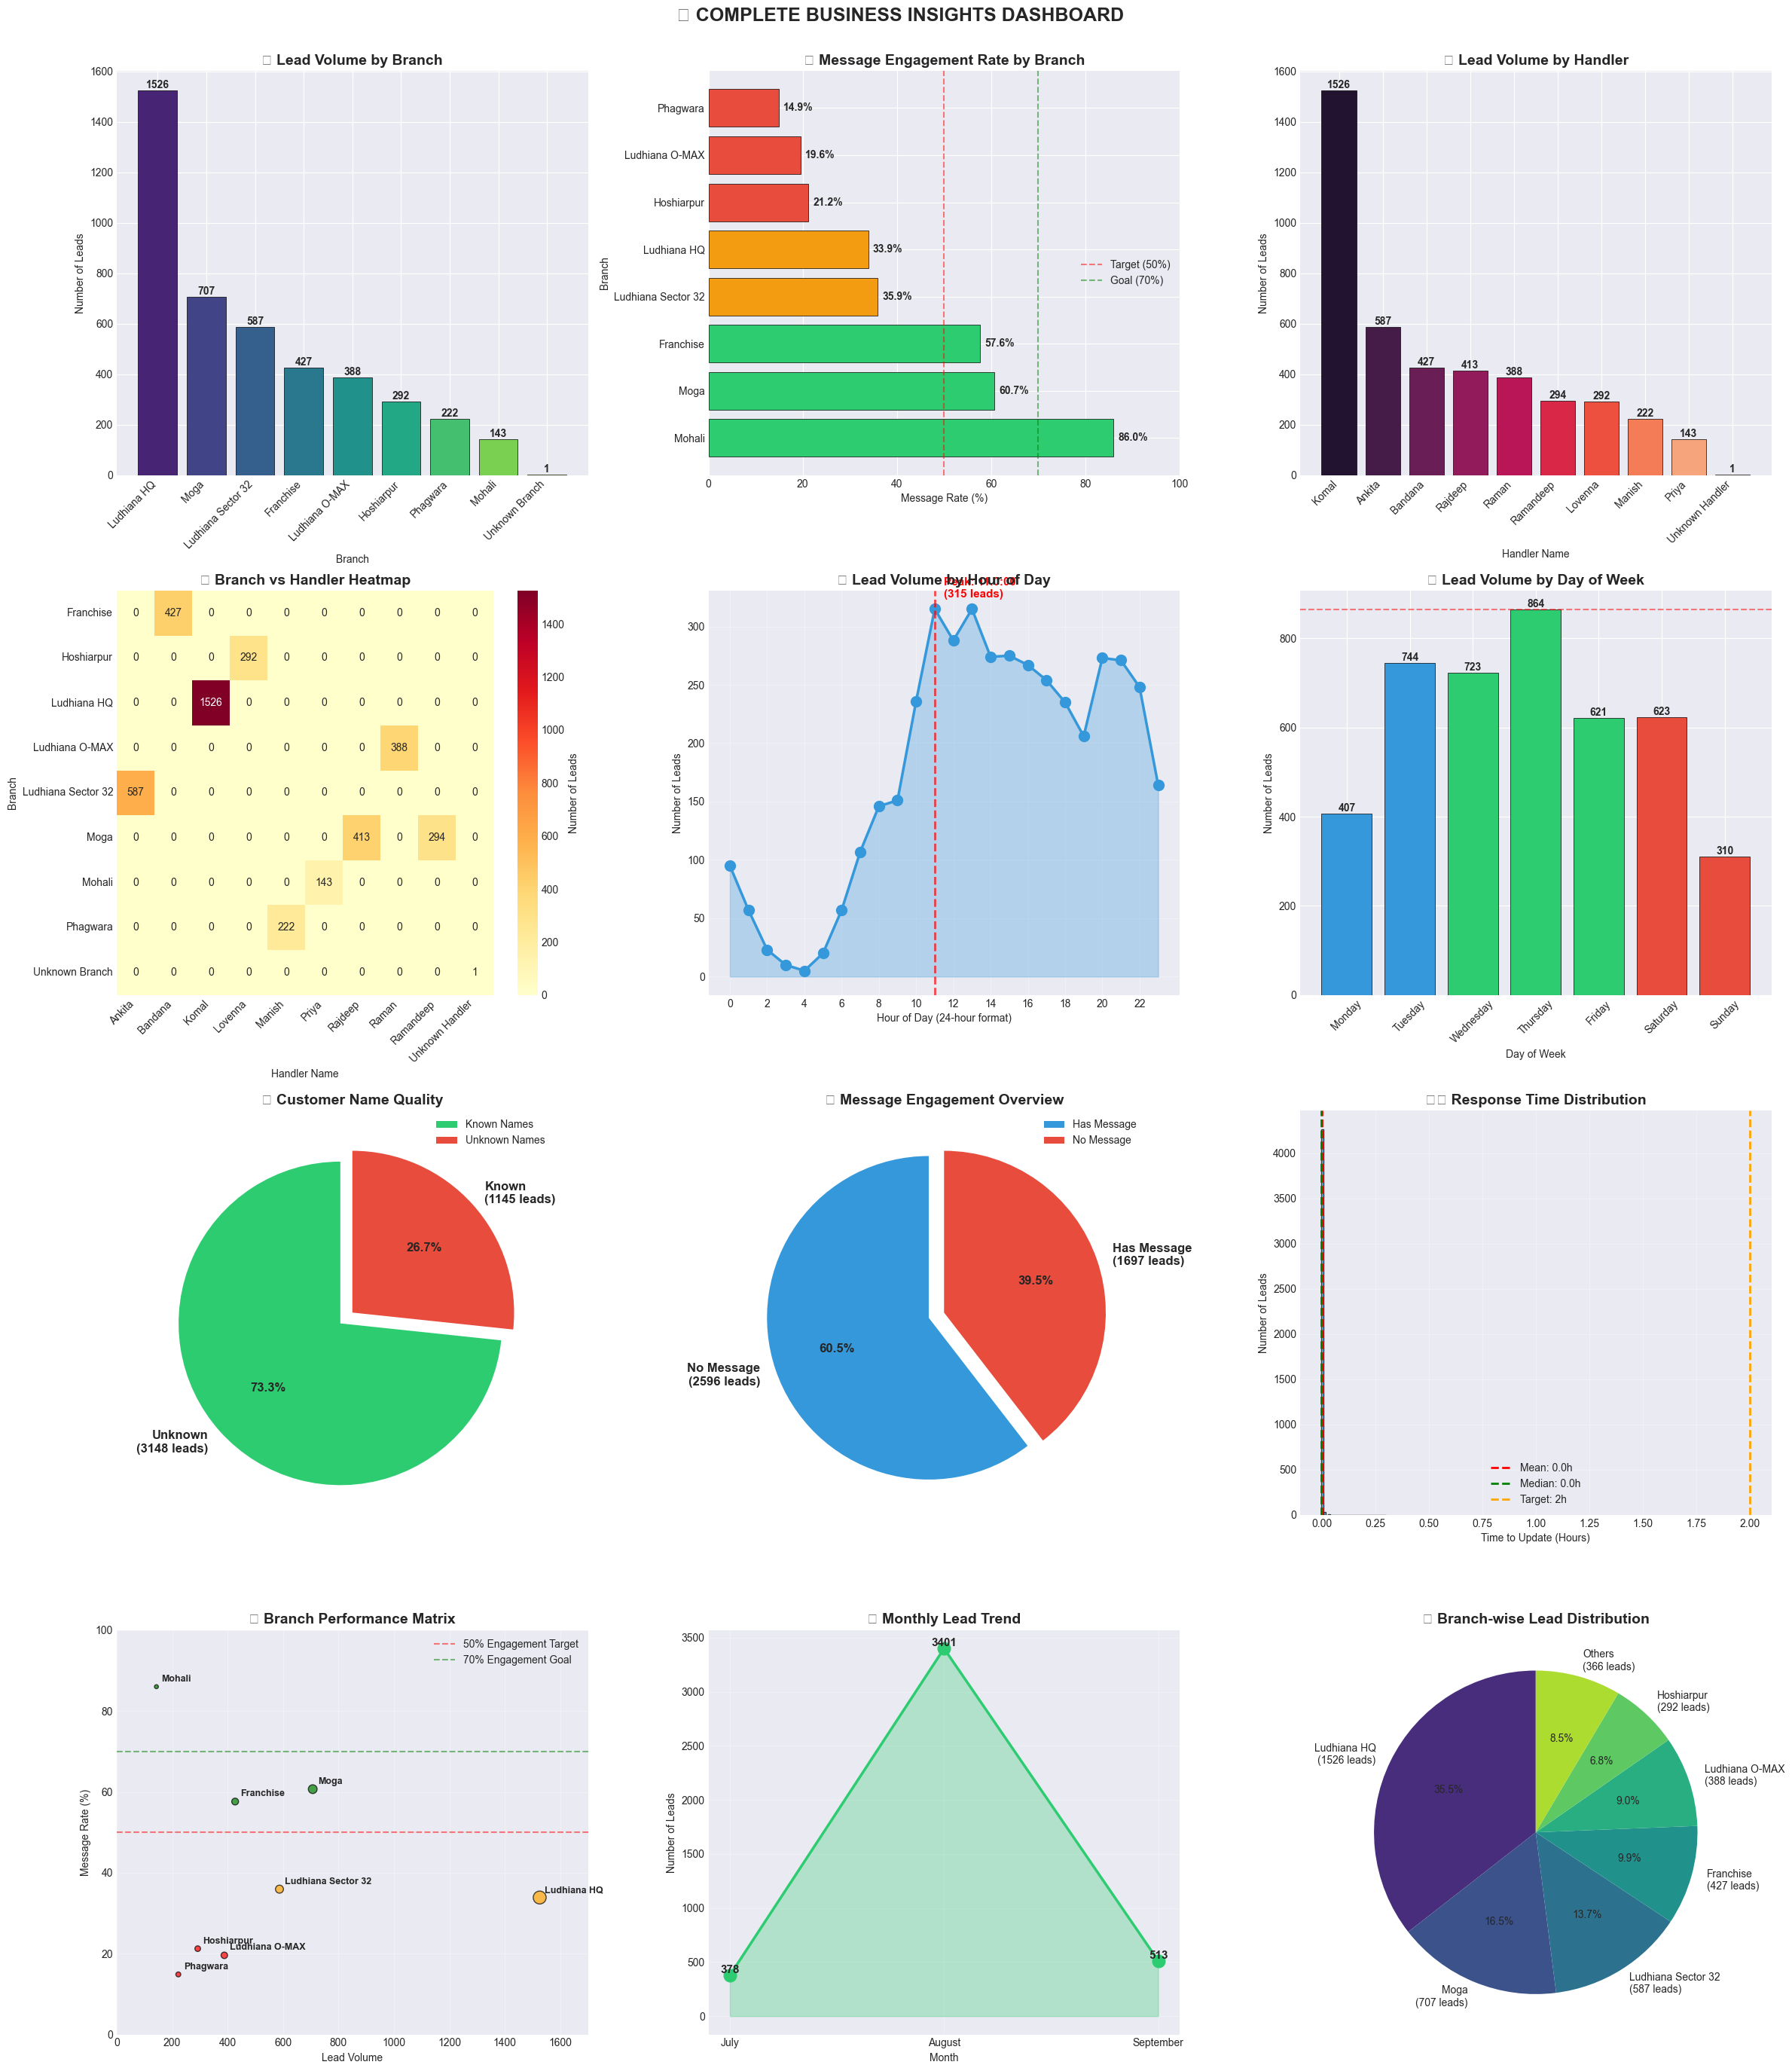


📊 GENERATING SPECIALIZED VISUALIZATIONS
✅ Heatmap saved as 'branch_day_heatmap.png'


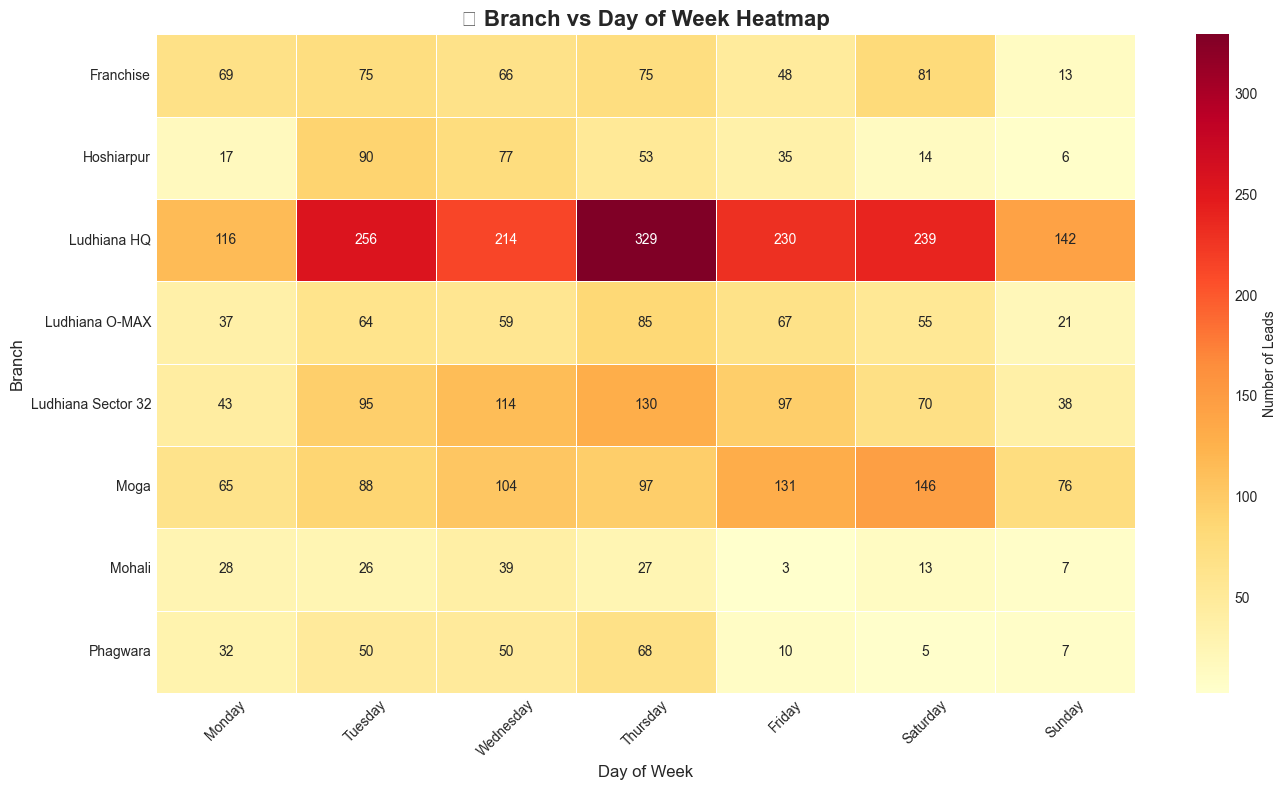

✅ Handler Performance saved as 'handler_performance.png'


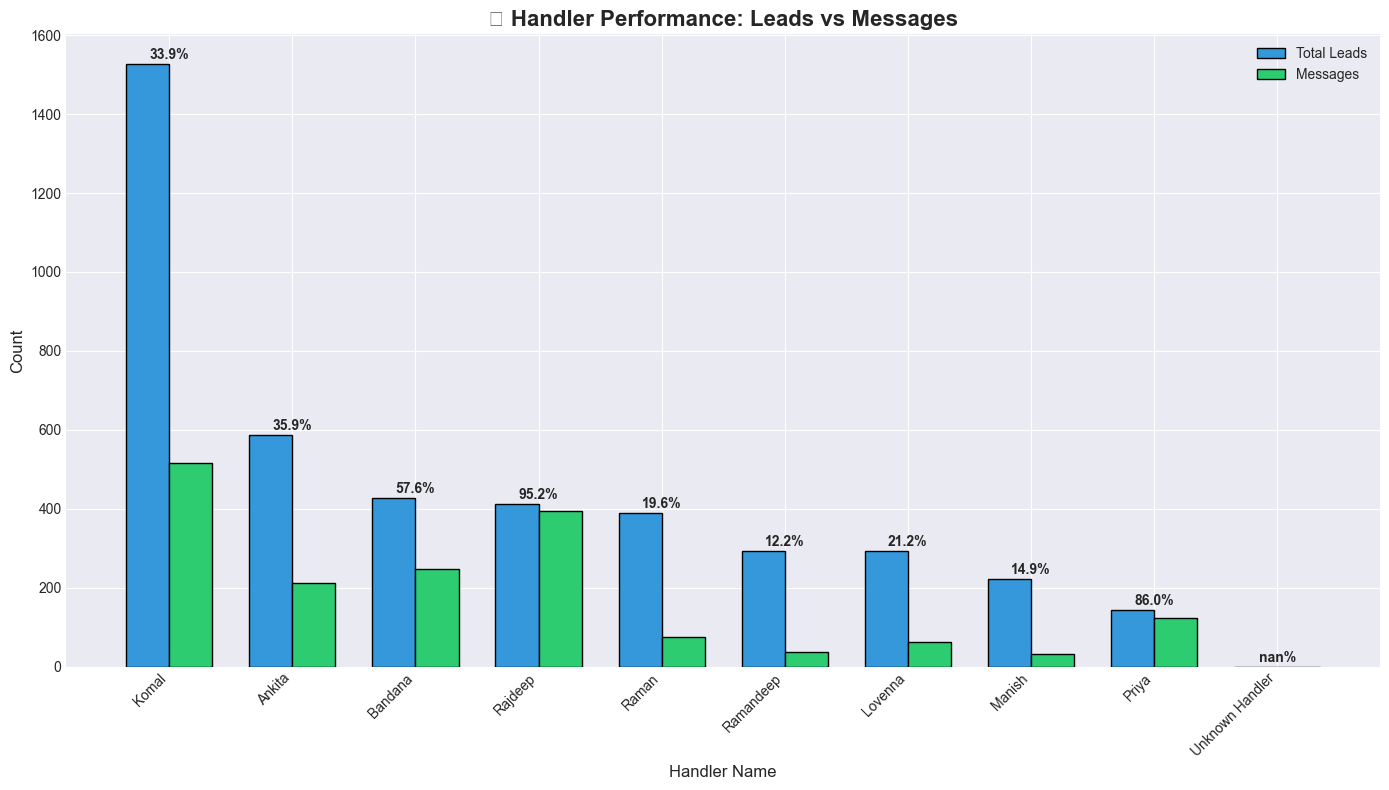

✅ Opportunity Matrix saved as 'opportunity_matrix.png'


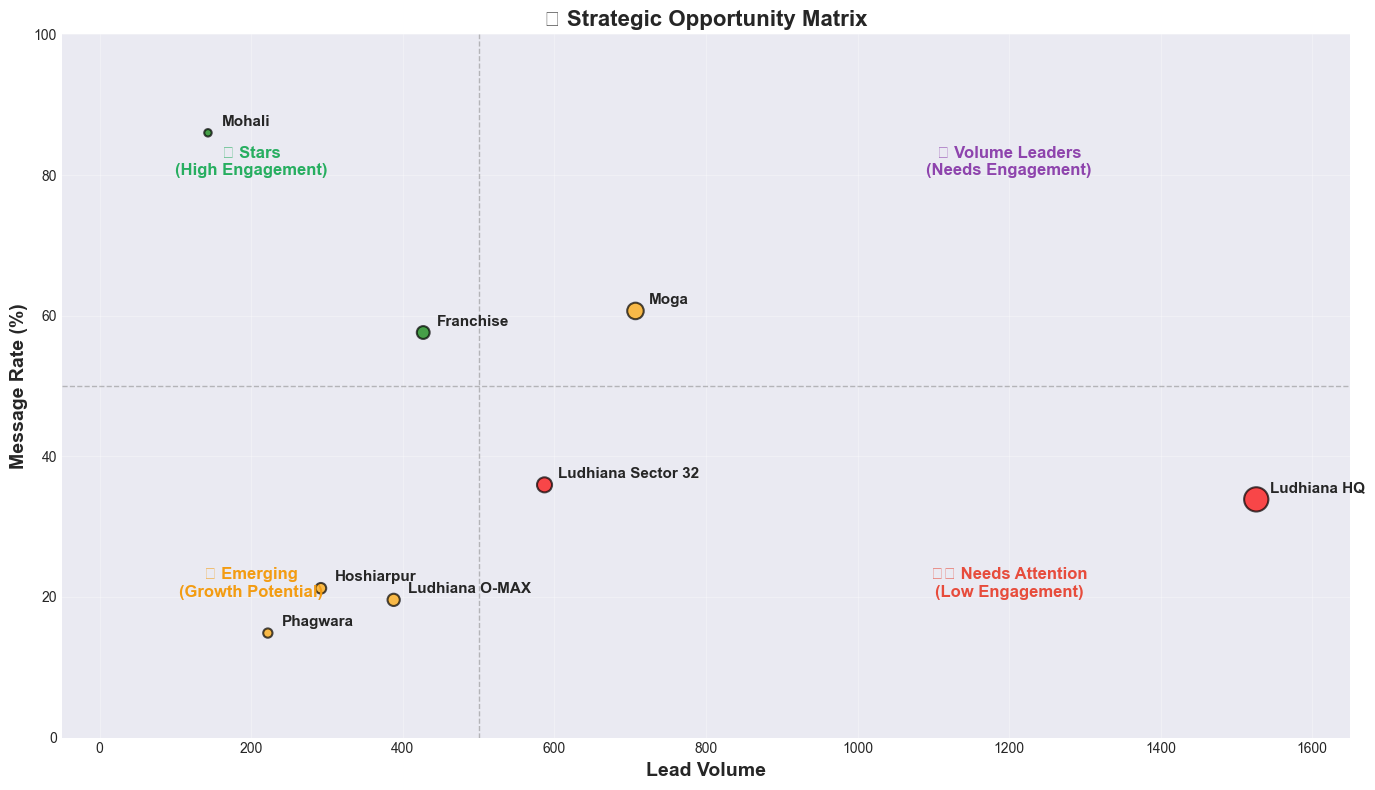


📊 PERFORMANCE SUMMARY TABLE

--------------------------------------------------------------------------------
🟢 HIGH Franchise:
   Volume:  427 leads | Messages:  246 | Rate:  57.6%
   Category: 🌱 Growth Opportunity
   📈 ACTION: Increase marketing spend - high conversion potential

🟡 MEDIUM Hoshiarpur:
   Volume:  292 leads | Messages:   62 | Rate:  21.2%
   Category: 📌 Monitor
   📊 ACTION: Monitor and implement gradual improvements

🔴 HIGH Ludhiana HQ:
   Volume: 1526 leads | Messages:  517 | Rate:  33.9%
   Category: ⚠️ Needs Improvement
   🚨 ACTION: URGENT - Improve engagement immediately

🟡 MEDIUM Ludhiana O-MAX:
   Volume:  388 leads | Messages:   76 | Rate:  19.6%
   Category: 📌 Monitor
   📊 ACTION: Monitor and implement gradual improvements

🔴 HIGH Ludhiana Sector 32:
   Volume:  587 leads | Messages:  211 | Rate:  35.9%
   Category: ⚠️ Needs Improvement
   🚨 ACTION: URGENT - Improve engagement immediately

🟡 MEDIUM Moga:
   Volume:  707 leads | Messages:  429 | Rate:  60.7%
  

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

# Set style for professional dashboards
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

# Create figure for dashboard
fig = plt.figure(figsize=(24, 28))

# --- 1. Branch Performance Overview ---
plt.subplot(4, 3, 1)
branch_data = df_clean['Branch'].value_counts()
colors = sns.color_palette("viridis", len(branch_data))
bars = plt.bar(branch_data.index, branch_data.values, color=colors, edgecolor='black', linewidth=0.5)
plt.title('🏢 Lead Volume by Branch', fontsize=14, fontweight='bold')
plt.xlabel('Branch')
plt.ylabel('Number of Leads')
plt.xticks(rotation=45, ha='right')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# --- 2. Message Engagement by Branch ---
plt.subplot(4, 3, 2)
branch_engagement = df_clean.groupby('Branch').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum()
}).rename(columns={'Lead ID': 'Total', 'Latest Message': 'Messages'})
branch_engagement['Message %'] = (branch_engagement['Messages'] / branch_engagement['Total'] * 100).round(1)
branch_engagement_sorted = branch_engagement.sort_values('Message %', ascending=False)

# Create horizontal bar chart
colors_engagement = ['#2ecc71' if x > 50 else '#f39c12' if x > 30 else '#e74c3c' 
                     for x in branch_engagement_sorted['Message %']]
bars = plt.barh(branch_engagement_sorted.index, branch_engagement_sorted['Message %'], 
                color=colors_engagement, edgecolor='black', linewidth=0.5)
plt.title('📱 Message Engagement Rate by Branch', fontsize=14, fontweight='bold')
plt.xlabel('Message Rate (%)')
plt.ylabel('Branch')
plt.xlim(0, 100)
for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2., 
             f'{width:.1f}%', ha='left', va='center', fontsize=10, fontweight='bold')
plt.axvline(x=50, color='red', linestyle='--', alpha=0.5, label='Target (50%)')
plt.axvline(x=70, color='green', linestyle='--', alpha=0.5, label='Goal (70%)')
plt.legend()

# --- 3. Handler Performance ---
plt.subplot(4, 3, 3)
handler_data = df_clean['Handler Name'].value_counts()
colors_handler = sns.color_palette("rocket", len(handler_data))
bars = plt.bar(handler_data.index, handler_data.values, color=colors_handler, edgecolor='black', linewidth=0.5)
plt.title('👤 Lead Volume by Handler', fontsize=14, fontweight='bold')
plt.xlabel('Handler Name')
plt.ylabel('Number of Leads')
plt.xticks(rotation=45, ha='right')
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# --- 4. Branch vs Handler Heatmap ---
plt.subplot(4, 3, 4)
cross_tab = pd.crosstab(df_clean['Branch'], df_clean['Handler Name'])
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlOrRd', cbar_kws={'label': 'Number of Leads'})
plt.title('📊 Branch vs Handler Heatmap', fontsize=14, fontweight='bold')
plt.xlabel('Handler Name')
plt.ylabel('Branch')
plt.xticks(rotation=45, ha='right')

# --- 5. Hourly Lead Distribution ---
plt.subplot(4, 3, 5)
hourly_data = df_clean['Contact Hour'].value_counts().sort_index()
plt.plot(hourly_data.index, hourly_data.values, marker='o', linewidth=2.5, markersize=10, color='#3498db')
plt.fill_between(hourly_data.index, 0, hourly_data.values, alpha=0.3, color='#3498db')
plt.title('⏰ Lead Volume by Hour of Day', fontsize=14, fontweight='bold')
plt.xlabel('Hour of Day (24-hour format)')
plt.ylabel('Number of Leads')
plt.xticks(range(0, 24, 2))
plt.grid(True, alpha=0.3)
peak_hour = hourly_data.idxmax()
peak_count = hourly_data.max()
plt.axvline(x=peak_hour, color='red', linestyle='--', alpha=0.7, linewidth=2)
plt.text(peak_hour + 0.5, peak_count + 10, f'Peak: {peak_hour}:00\n({peak_count} leads)', 
         fontsize=11, fontweight='bold', color='red')

# --- 6. Daily Lead Distribution ---
plt.subplot(4, 3, 6)
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_data = df_clean['Contact Day'].value_counts()
day_data = day_data.reindex(day_order)
colors_day = ['#2ecc71' if day in ['Wednesday', 'Thursday', 'Friday'] else '#e74c3c' if day in ['Saturday', 'Sunday'] else '#3498db' 
              for day in day_data.index]
bars = plt.bar(day_data.index, day_data.values, color=colors_day, edgecolor='black', linewidth=0.5)
plt.title('📅 Lead Volume by Day of Week', fontsize=14, fontweight='bold')
plt.xlabel('Day of Week')
plt.ylabel('Number of Leads')
plt.xticks(rotation=45)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height,
             f'{int(height)}', ha='center', va='bottom', fontsize=10, fontweight='bold')
peak_day = day_data.idxmax()
plt.axhline(y=day_data.max(), color='red', linestyle='--', alpha=0.5)

# --- 7. Customer Name Quality ---
plt.subplot(4, 3, 7)
name_data = df_clean['Customer Name'].apply(lambda x: 'Known' if x != 'Unknown' else 'Unknown')
name_counts = name_data.value_counts()
colors_pie = ['#2ecc71', '#e74c3c']
explode = (0.1, 0)
plt.pie(name_counts.values, labels=[f'{label}\n({count} leads)' for label, count in name_counts.items()], 
        autopct='%1.1f%%', colors=colors_pie, startangle=90, explode=explode,
        textprops={'fontsize': 12, 'fontweight': 'bold'})
plt.title('👤 Customer Name Quality', fontsize=14, fontweight='bold')
plt.legend(['Known Names', 'Unknown Names'], loc='upper right')

# --- 8. Message Engagement Distribution ---
plt.subplot(4, 3, 8)
message_data = df_clean['Latest Message'].apply(lambda x: 'Has Message' if x != '' else 'No Message')
message_counts = message_data.value_counts()
colors_message = ['#3498db', '#e74c3c']
explode = (0.1, 0)
plt.pie(message_counts.values, labels=[f'{label}\n({count} leads)' for label, count in message_counts.items()], 
        autopct='%1.1f%%', colors=colors_message, startangle=90, explode=explode,
        textprops={'fontsize': 12, 'fontweight': 'bold'})
plt.title('💬 Message Engagement Overview', fontsize=14, fontweight='bold')
plt.legend(['Has Message', 'No Message'], loc='upper right')

# --- 9. Response Time Distribution ---
plt.subplot(4, 3, 9)
response_times = df_clean[df_clean['Time to Update (Hours)'] >= 0]['Time to Update (Hours)']
plt.hist(response_times, bins=30, edgecolor='black', alpha=0.7, color='#3498db')
plt.title('⏱️ Response Time Distribution', fontsize=14, fontweight='bold')
plt.xlabel('Time to Update (Hours)')
plt.ylabel('Number of Leads')
plt.axvline(x=response_times.mean(), color='red', linestyle='--', 
            label=f'Mean: {response_times.mean():.1f}h', linewidth=2)
plt.axvline(x=response_times.median(), color='green', linestyle='--', 
            label=f'Median: {response_times.median():.1f}h', linewidth=2)
plt.axvline(x=2, color='orange', linestyle='--', label='Target: 2h', linewidth=2)
plt.legend()
plt.grid(True, alpha=0.3)

# --- 10. Branch Performance Matrix (Message Rate vs Volume) ---
plt.subplot(4, 3, 10)
branch_perf = df_clean.groupby('Branch').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum()
}).rename(columns={'Lead ID': 'Volume', 'Latest Message': 'Messages'})
branch_perf['Message %'] = (branch_perf['Messages'] / branch_perf['Volume'] * 100)

# Create scatter plot
colors_scatter = ['red' if x < 30 else 'orange' if x < 50 else 'green' for x in branch_perf['Message %']]
sizes = branch_perf['Volume'] / 10
plt.scatter(branch_perf['Volume'], branch_perf['Message %'], 
            s=sizes, c=colors_scatter, alpha=0.7, edgecolors='black', linewidth=1)
plt.axhline(y=50, color='red', linestyle='--', alpha=0.5, label='50% Engagement Target')
plt.axhline(y=70, color='green', linestyle='--', alpha=0.5, label='70% Engagement Goal')
plt.title('🎯 Branch Performance Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Lead Volume')
plt.ylabel('Message Rate (%)')
plt.xlim(0, 1700)
plt.ylim(0, 100)

# Add branch labels
for idx, row in branch_perf.iterrows():
    plt.annotate(idx, (row['Volume'], row['Message %']), 
                 fontsize=9, fontweight='bold', 
                 xytext=(5, 5), textcoords='offset points')
plt.legend()
plt.grid(True, alpha=0.3)

# --- 11. Monthly Trend ---
plt.subplot(4, 3, 11)
monthly_data = df_clean['Contact Month'].value_counts()
month_order = ['July', 'August', 'September']
monthly_data = monthly_data.reindex(month_order)
plt.plot(monthly_data.index, monthly_data.values, marker='o', linewidth=2.5, 
         markersize=12, color='#2ecc71')
plt.fill_between(monthly_data.index, 0, monthly_data.values, alpha=0.3, color='#2ecc71')
plt.title('📈 Monthly Lead Trend', fontsize=14, fontweight='bold')
plt.xlabel('Month')
plt.ylabel('Number of Leads')
for i, (month, count) in enumerate(monthly_data.items()):
    plt.text(i, count + 20, f'{count}', ha='center', fontsize=11, fontweight='bold')
plt.grid(True, alpha=0.3)

# --- 12. Branch Lead Distribution (Pie Chart) ---
plt.subplot(4, 3, 12)
branch_pie = df_clean['Branch'].value_counts()
# Show top 6 branches, combine others
if len(branch_pie) > 6:
    top6 = branch_pie.head(6)
    others = pd.Series({'Others': branch_pie[6:].sum()})
    branch_pie = pd.concat([top6, others])
colors_pie2 = sns.color_palette("viridis", len(branch_pie))
plt.pie(branch_pie.values, labels=[f'{label}\n({count} leads)' for label, count in branch_pie.items()], 
        autopct='%1.1f%%', colors=colors_pie2, startangle=90,
        textprops={'fontsize': 10})
plt.title('🌍 Branch-wise Lead Distribution', fontsize=14, fontweight='bold')

plt.suptitle('📊 COMPLETE BUSINESS INSIGHTS DASHBOARD', fontsize=18, fontweight='bold', y=0.98)
plt.tight_layout()
plt.subplots_adjust(top=0.95)
plt.savefig('complete_business_dashboard.png', dpi=300, bbox_inches='tight')
print("✅ Dashboard saved as 'complete_business_dashboard.png'")

plt.show()

# --- Generate additional specialized visualizations ---

print("\n" + "="*80)
print("📊 GENERATING SPECIALIZED VISUALIZATIONS")
print("="*80)

# 1. Branch Engagement Heatmap
fig2, ax = plt.subplots(figsize=(14, 8))
branch_day_heatmap = pd.crosstab(df_clean['Branch'], df_clean['Contact Day'])
branch_day_heatmap = branch_day_heatmap.reindex(columns=day_order)
sns.heatmap(branch_day_heatmap, annot=True, fmt='d', cmap='YlOrRd', 
            cbar_kws={'label': 'Number of Leads'}, linewidths=0.5, linecolor='white')
plt.title('📊 Branch vs Day of Week Heatmap', fontsize=16, fontweight='bold')
plt.xlabel('Day of Week', fontsize=12)
plt.ylabel('Branch', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('branch_day_heatmap.png', dpi=300, bbox_inches='tight')
print("✅ Heatmap saved as 'branch_day_heatmap.png'")
plt.show()

# 2. Handler Performance Comparison
fig3, ax = plt.subplots(figsize=(14, 8))
handler_perf = df_clean.groupby('Handler Name').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum()
}).rename(columns={'Lead ID': 'Total', 'Latest Message': 'Messages'})
handler_perf['Message %'] = (handler_perf['Messages'] / handler_perf['Total'] * 100).round(1)
handler_perf_sorted = handler_perf.sort_values('Total', ascending=False)

x = np.arange(len(handler_perf_sorted))
width = 0.35

bars1 = ax.bar(x - width/2, handler_perf_sorted['Total'], width, label='Total Leads', color='#3498db', edgecolor='black')
bars2 = ax.bar(x + width/2, handler_perf_sorted['Messages'], width, label='Messages', color='#2ecc71', edgecolor='black')

ax.set_xlabel('Handler Name', fontsize=12)
ax.set_ylabel('Count', fontsize=12)
ax.set_title('👤 Handler Performance: Leads vs Messages', fontsize=16, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(handler_perf_sorted.index, rotation=45, ha='right')
ax.legend()

# Add percentage labels
for i, (idx, row) in enumerate(handler_perf_sorted.iterrows()):
    ax.text(i, row['Total'] + 5, f"{row['Message %']:.1f}%", 
            ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.savefig('handler_performance.png', dpi=300, bbox_inches='tight')
print("✅ Handler Performance saved as 'handler_performance.png'")
plt.show()

# 3. Opportunity Matrix
fig4, ax = plt.subplots(figsize=(14, 8))

# Calculate opportunity scores
branch_opp = df_clean.groupby('Branch').agg({
    'Lead ID': 'count',
    'Latest Message': lambda x: (x != '').sum()
}).rename(columns={'Lead ID': 'Volume', 'Latest Message': 'Messages'})
branch_opp['Message %'] = (branch_opp['Messages'] / branch_opp['Volume'] * 100)

# Create scatter plot with quadrants
sizes = branch_opp['Volume'] / 5
colors_opp = ['red' if row['Volume'] > 500 and row['Message %'] < 40 else 
              'green' if row['Message %'] > 50 and row['Volume'] < 500 else 
              'orange' for idx, row in branch_opp.iterrows()]

scatter = ax.scatter(branch_opp['Volume'], branch_opp['Message %'], 
                    s=sizes, c=colors_opp, alpha=0.7, edgecolors='black', linewidth=1.5)

ax.axhline(y=50, color='gray', linestyle='--', alpha=0.5, linewidth=1)
ax.axvline(x=500, color='gray', linestyle='--', alpha=0.5, linewidth=1)

# Add quadrant labels
ax.text(1200, 80, '🟣 Volume Leaders\n(Needs Engagement)', ha='center', fontsize=12, fontweight='bold', color='#8e44ad')
ax.text(200, 80, '🌟 Stars\n(High Engagement)', ha='center', fontsize=12, fontweight='bold', color='#27ae60')
ax.text(1200, 20, '⚠️ Needs Attention\n(Low Engagement)', ha='center', fontsize=12, fontweight='bold', color='#e74c3c')
ax.text(200, 20, '🌱 Emerging\n(Growth Potential)', ha='center', fontsize=12, fontweight='bold', color='#f39c12')

# Add branch labels
for idx, row in branch_opp.iterrows():
    ax.annotate(idx, (row['Volume'], row['Message %']), 
               fontsize=11, fontweight='bold', 
               xytext=(10, 5), textcoords='offset points')

ax.set_xlabel('Lead Volume', fontsize=14, fontweight='bold')
ax.set_ylabel('Message Rate (%)', fontsize=14, fontweight='bold')
ax.set_title('🎯 Strategic Opportunity Matrix', fontsize=16, fontweight='bold')
ax.set_xlim(-50, 1650)
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('opportunity_matrix.png', dpi=300, bbox_inches='tight')
print("✅ Opportunity Matrix saved as 'opportunity_matrix.png'")
plt.show()

# --- Performance Summary Table with Visual Indicators ---
print("\n" + "="*80)
print("📊 PERFORMANCE SUMMARY TABLE")
print("="*80)

# Create summary DataFrame with color indicators
performance_summary = branch_opp.copy()
performance_summary['Performance Category'] = np.where(
    (performance_summary['Volume'] > 500) & (performance_summary['Message %'] >= 50), '🌟 Star Performer',
    np.where(
        (performance_summary['Volume'] > 500) & (performance_summary['Message %'] < 40), '⚠️ Needs Improvement',
        np.where(
            (performance_summary['Volume'] <= 500) & (performance_summary['Message %'] >= 50), '🌱 Growth Opportunity',
            '📌 Monitor'
        )
    )
)
performance_summary['Priority'] = np.where(
    performance_summary['Performance Category'].isin(['⚠️ Needs Improvement']), '🔴 HIGH',
    np.where(
        performance_summary['Performance Category'].isin(['🌱 Growth Opportunity']), '🟢 HIGH',
        '🟡 MEDIUM'
    )
)

print("\n" + "-"*80)
for idx, row in performance_summary.iterrows():
    print(f"{row['Priority']} {idx}:")
    print(f"   Volume: {row['Volume']:>4} leads | Messages: {row['Messages']:>4} | Rate: {row['Message %']:>5.1f}%")
    print(f"   Category: {row['Performance Category']}")
    if '🌟' in row['Performance Category']:
        print("   🎯 ACTION: Maintain excellence and document best practices")
    elif '⚠️' in row['Performance Category']:
        print("   🚨 ACTION: URGENT - Improve engagement immediately")
    elif '🌱' in row['Performance Category']:
        print("   📈 ACTION: Increase marketing spend - high conversion potential")
    else:
        print("   📊 ACTION: Monitor and implement gradual improvements")
    print()

print("\n" + "="*80)
print("✅ ALL VISUALIZATIONS COMPLETE!")
print("="*80)

print("\n📁 FILES GENERATED:")
print("1. complete_business_dashboard.png - Main dashboard (12 charts)")
print("2. branch_day_heatmap.png - Branch vs Day heatmap")
print("3. handler_performance.png - Handler comparison chart")
print("4. opportunity_matrix.png - Strategic opportunity matrix")

print("\n💡 USE THESE VISUALIZATIONS FOR:")
print("• Team meetings and presentations")
print("• Performance reviews")
print("• Strategic planning sessions")
print("• Training materials")
print("• Weekly/monthly reporting")

print("\n" + "="*80)
print("🎉 ANALYSIS AND VISUALIZATION COMPLETE!")
print("="*80)